<a href="https://colab.research.google.com/github/DanisStepanov/image_processing/blob/main/%D0%9F%D1%80%D0%B0%D0%BA%D1%82%D0%B8%D1%87%D0%B5%D1%81%D0%BA%D0%B0%D1%8F_%D1%80%D0%B0%D0%B1%D0%BE%D1%82%D0%B0_%E2%84%965_%D0%9A%D0%BB%D0%B0%D1%81%D1%81%D0%B8%D1%84%D0%B8%D0%BA%D0%B0%D1%86%D0%B8%D1%8F_%D0%B8_%D0%BA%D0%BB%D0%B0%D1%81%D1%82%D0%B5%D1%80%D0%B8%D0%B7%D0%B0%D1%86%D0%B8%D1%8F_%D1%81%D0%BF%D1%83%D1%82%D0%BD%D0%B8%D0%BA%D0%BE%D0%B2%D1%8B%D1%85_%D1%81%D0%BD%D0%B8%D0%BC%D0%BA%D0%BE%D0%B2_%D0%B2_GEE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Практическая работа №5. Сравнительный анализ контролируемой классификации и неконтролируемой кластеризации спутниковых снимков в Google Earth Engine: выявление ошибок пропуска и скрытых пространственных структур**

## **1. Цель работы**

Обучить в Google Earth Engine классификаторы земного покрова по разметке Dynamic World и честно оценить их точность, найти кластеризацией на снимке территории объекты, которых нет в легенде готовых карт, и экспериментально определить, когда кластеризация цветов действительно уменьшает размер изображений.

## **2. Задачи работы**

1.  **Подготовить** летний композит Sentinel-2 и карту Dynamic World для территории своего варианта, рассмотреть снимок в естественных цветах и в инфракрасной комбинации каналов и записать гипотезы о том, что на нём можно найти;
2.  **Обучить** несколько классификаторов GEE на стратифицированной выборке с метками Dynamic World, сравнить случайную и пространственную проверку точности, оценить точность по классам и важность признаков;
3.  **Построить** карту классификации территории и сравнить её с картой Dynamic World;
4.  **Кластеризовать** снимок алгоритмом K-средних на серверах GEE при нескольких значениях $K$, дать кластерам названия, найти малые и необычные группы пикселей и проверить гипотезы;
5.  **Провести** эксперименты по сжатию фотографий, карты и снимка кластеризацией цветов: размер файлов, время, качество, сравнение со встроенным методом квантизации;
6.  **Сформулировать** выводы с конкретными числами.

> **Примечание.** Работа опирается на две лекции:
> - [лекция «Экспорт растровых данных и применение методов машинного обучения в среде Google Earth Engine»](https://colab.research.google.com/drive/1BU-Q4D0XEIy2KiEtzw-3dKISE0lwGLV2) — **Разделы 1–4** (композиты, экспорт, выборки, классификаторы);
> - лекция «Кластеризация спутниковых снимков в среде Google Earth Engine» — **Разделы 2–6** (K-средних, интерпретация кластеров, поиск необычного, сжатие изображений).
>
> Код из лекций можно использовать как образец, но задания этой работы отличаются от лекционных примеров: другая разметка, другая территория, другие проверки.

> 📝 **Как выполнять работу.** Выполняйте ячейки по порядку. В ячейки `# Ваш код` впишите свой код; если в ячейке уже есть заготовка, замените в ней `...`. Ответы на вопросы пишите в ячейки **Ответ:** — двойной щелчок по ячейке, текст ответа, затем Shift+Enter. В ответах приводите числа из своих результатов.

---

## **3. Выбор территории и подготовка данных в Google Earth Engine**

### **3.1. Настройка рабочей среды и аутентификация**

In [1]:
%%capture
!pip install -U geemap geedim rasterio scikit-learn scikit-image

In [2]:
# Импорт основных библиотек для работы
import os
import time

import ee                        # Google Earth Engine
import geemap                    # Интерактивные карты и экспорт растров из GEE
import numpy as np               # Работа с массивами
import pandas as pd              # Работа с таблицами
import rasterio                  # Чтение экспортированных GeoTIFF
import matplotlib.pyplot as plt  # Построение графиков
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from PIL import Image            # Сохранение изображений, в том числе палитровых PNG
from sklearn.cluster import KMeans
from skimage import data as skdata
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

%config InlineBackend.figure_format = 'jpeg'  # рисунки со снимками компактнее в JPEG

Перед началом работы с geemap и Google Earth Engine необходимо:

- **Зарегистрировать аккаунт Google Earth Engine**: Перейдите на [https://code.earthengine.google.com/register](https://code.earthengine.google.com/register) для создания аккаунта GEE. После регистрации нужно настроить проект Google Cloud и активировать API Earth Engine, следуя инструкциям [здесь](https://docs.google.com/document/d/1ZGSmrNm6_baqd8CHt33kIBWOlvkh-HLr46bODgJN1h0/edit?usp=sharing). GEE бесплатен для [некоммерческого и исследовательского использования](https://earthengine.google.com/noncommercial).

- **Проверить аутентификацию API**: Чтобы убедиться в правильности настройки аккаунта Earth Engine, запустите [этот тестовый блокнот](https://colab.research.google.com/github/gee-community/geemap/blob/master/docs/notebooks/geemap_colab.ipynb) в Google Colab.

In [3]:
# Ваш код: ee.Authenticate() и ee.Initialize(project=...) с именем вашего проекта

In [4]:
ee.Authenticate()
ee.Initialize(project='cedar-bot-510810-r8')

### **3.2. Выбор территории**

Ниже перечислены территории, на которых есть объекты, плохо заметные на снимке в естественных цветах или отсутствующие в легенде готовых карт земного покрова: месторождения полезных ископаемых, нефтепромыслы, лесные гари, солепромыслы. Что именно и где искать, в таблице не сказано — это и предстоит выяснить. Номер варианта назначает преподаватель (если не назначен — номер в списке группы по модулю 7, нулю соответствует вариант 7).

#### **Таблица 1. Варианты территорий**

| **Вариант** | **Территория** | **Широта, долгота центра** | **Природная зона** |
|---|---|---|---|
| 1 | Олимпиадинское золоторудное месторождение, Красноярский край | 59.585, 92.990 | Южная тайга |
| 2 | Норильск: медно-никелевые и платиноидные руды, Красноярский край | 69.350, 88.200 | Лесотундра |
| 3 | Губкин, железные руды Курской магнитной аномалии, Белгородская область | 51.290, 37.700 | Лесостепь |
| 4 | Железногорск, железные руды Курской магнитной аномалии, Курская область | 52.360, 35.400 | Лесостепь |
| 5 | Самотлорское нефтяное месторождение, Ханты-Мансийский АО | 61.130, 76.750 | Средняя тайга, болота |
| 6 | Тайга в Забайкальском крае, район весенних лесных пожаров 2024 года | 54.665, 118.893 | Горная тайга |
| 7 | Озеро Баскунчак, Астраханская область | 48.200, 46.880 | Полупустыня |

Область интереса — квадрат 14×14 км вокруг центра. Все варианты анализируются по снимкам лета 2024 года.

In [5]:
PLACES = {
    1: ('Олимпиадинское золоторудное месторождение', 59.585, 92.990),
    2: ('Норильск', 69.350, 88.200),
    3: ('Губкин, Лебединский ГОК', 51.290, 37.700),
    4: ('Железногорск, Михайловский ГОК', 52.360, 35.400),
    5: ('Самотлорское нефтяное месторождение', 61.130, 76.750),
    6: ('Тайга в Забайкальском крае', 54.665, 118.893),
    7: ('Озеро Баскунчак', 48.200, 46.880),
}
YEAR = 2024

In [6]:
VARIANT = ...   # номер вашего варианта
# Ваш код: PLACE, LAT, LON = PLACES[VARIANT]; roi — квадрат 14×14 км: ee.Geometry.Point([LON, LAT]).buffer(7000).bounds()
# Ваш код: карта geemap с подложкой 'Esri.WorldImagery' и контуром roi

In [7]:
VARIANT = 6
PLACE, LAT, LON = PLACES[VARIANT]
roi = ee.Geometry.Point([LON, LAT]).buffer(7000).bounds()

m = geemap.Map(center=[LAT, LON], zoom=10)
m.add_basemap('Esri.WorldImagery')
m.add_layer(roi, {'color': 'red'}, 'ROI')
m

Map(center=[54.665, 118.893], controls=(WidgetControl(options=['position', 'transparent_bg'], position='toprig…

**Задание 3.2.** Рассмотрите территорию на карте-подложке. Ответьте до начала анализа.

**Вопрос:** Какие типы земного покрова вы видите на подложке? Какие объекты, связанные с названием территории (добыча, промыслы, пожары), вы ожидаете найти и где? Какие из них, по-вашему, не имеют своего класса в легенде Dynamic World (вода, деревья, трава, затопляемая растительность, сельхозкультуры, кустарники, застройка, голая земля, снег и лёд)?

**Ответ:**
Деревья, кустарники, голая земля, вода.

Добыча можно искать вдоль рек(может золотишко воляется), промыслы(может избы охотников стоят или чот типа такого)

Пожары, карьеры, вырубки

### **3.3. Летний композит Sentinel-2 и спектральные индексы**

> 📚 **Подсказка:** [лекция по GEE](https://colab.research.google.com/drive/1BU-Q4D0XEIy2KiEtzw-3dKISE0lwGLV2), **разделы 2.2–2.3** (фильтрация, маска облаков по каналу SCL, медианный композит) и **3.3** (индексы).

**Задание 3.3.** Постройте медианный композит `composite` снимков Sentinel-2 уровня 2A (`COPERNICUS/S2_SR_HARMONIZED`) за 1 июня – 31 августа 2024 года:
- каналы `BANDS = ['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12']`, значения отражения переведены в диапазон 0–1 (деление на 10000);
- снимки с облачностью `CLOUDY_PIXEL_PERCENTAGE` < 20%, облака и тени замаскированы по каналу SCL (классы 3, 8, 9, 10);
- к композиту добавлены индексы `NDVI` (B8, B4), `NDWI` (B3, B8) и `NDBI` (B11, B8);
- список всех признаков сохраните в переменную `FEATURES` — он понадобится для обучения классификаторов.

In [8]:
s2 = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
      .filterBounds(roi)
      .filterDate('2024-08-01', '2024-09-30')
      .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 20)))
s2 = s2.map(lambda img: img.updateMask(
    img.select('SCL').neq(3)
    .And(img.select('SCL').neq(8))
    .And(img.select('SCL').neq(9))
    .And(img.select('SCL').neq(10))
))

BANDS = ['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12']
composite = s2.select(BANDS).median().divide(10000)

NDVI = composite.normalizedDifference(['B8', 'B4']).rename('NDVI')
NDWI = composite.normalizedDifference(['B3', 'B8']).rename('NDWI')
NDBI = composite.normalizedDifference(['B11', 'B8']).rename('NDBI')
NBR = composite.normalizedDifference(['B12', 'B8A']).rename('NBR')

composite = composite.addBands([NDVI, NDWI, NDBI, NBR])
FEATURES = composite.bandNames()

print( FEATURES.getInfo())


['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12', 'NDVI', 'NDWI', 'NDBI', 'NBR']


### **3.4. Карта Dynamic World**

Dynamic World — карта земного покрова с пикселем 10 м, которую Google строит нейросетью для каждого снимка Sentinel-2. В этой работе она служит **разметкой для обучения**: классификатор будет учиться повторять её классы по спектру пикселей.

**Задание 3.4.** Получите `dynamic_world` — моду канала `label` коллекции `GOOGLE/DYNAMICWORLD/V1` за тот же период (наиболее частый класс в каждом пикселе), обрежьте по `roi` и переименуйте канал в `'class'`.

In [9]:
DW_NAMES = ['Вода', 'Деревья', 'Трава', 'Затопл. растительность', 'Культуры',
            'Кустарники', 'Застройка', 'Голая земля', 'Снег и лед']
DW_COLORS = ['#419bdf', '#397d49', '#88b053', '#7a87c6', '#e49635',
             '#dfc35a', '#c4281b', '#a59b8f', '#b39fe1']

In [10]:
dynamic_world = (ee.ImageCollection('GOOGLE/DYNAMICWORLD/V1')
                 .filterBounds(roi)
                 .filterDate('2024-08-01', '2024-09-30')
                 .reduce(ee.Reducer.mode())
                 .select('label_mode')   # <-- после reduce() канал называется label_mode
                 .clip(roi)
                 .rename('class'))

### **3.5. Экспорт и просмотр растров**

Для анализа на локальной машине нужны шесть основных каналов композита, индексы NDVI и NDWI и карта Dynamic World. Растры экспортируются в проекции UTM с пикселем 10 м и загружаются плитками 256×256 пикселей. Карты классов сохраняются с типом `int16`: при типе `uint8` значение 0 используется как «нет данных» и совпало бы с классом «Вода». **Если экспорт идёт слишком долго, увеличьте `SCALE` до 20 м.**

In [11]:
#@title Готовая функция экспорта
SCALE = 10  # размер пикселя, м

def utm_crs(region):
    """Код EPSG зоны UTM для центра области."""
    lon, lat = region.centroid(maxError=1).coordinates().getInfo()
    return f'EPSG:{(32600 if lat >= 0 else 32700) + int((lon + 180) // 6) + 1}'

def export_georeferenced_raster(image, region, filename, scale=SCALE, dtype='float32', tile_size=256):
    """Экспорт в GeoTIFF в проекции UTM с загрузкой плитками."""
    geemap.download_ee_image(image=image, filename=filename, region=region, scale=scale,
                             crs=utm_crs(region), dtype=dtype, max_tile_dim=tile_size)
    return filename

def read_raster(filename):
    """Массив каналов растра (каналы, строки, столбцы)."""
    with rasterio.open(filename) as src:
        return src.read()

os.makedirs('data', exist_ok=True)

**Задание 3.5.** Экспортируйте каналы `LOCAL_BANDS` композита в `data/sentinel2.tif` (тип `float32`) и `dynamic_world` в `data/dynamic_world.tif` (тип `int16`). Загрузите их в массивы `bands` и `dw`, получите маску пикселей с данными `valid` (все каналы конечны и `dw >= 0`), размеры `H`, `W` и площадь пикселя в гектарах `PIXEL_AREA_HA`.

In [12]:
LOCAL_BANDS = ['B2', 'B3', 'B4', 'B8', 'B11', 'B12', 'NDVI', 'NDWI']

In [13]:
export_georeferenced_raster(
    composite.select(LOCAL_BANDS), roi, 'data/sentinel2.tif',
    scale=SCALE, dtype='float32'
)
export_georeferenced_raster(
    dynamic_world, roi, 'data/dynamic_world.tif',
    scale=SCALE, dtype='int16'
)
bands = read_raster('data/sentinel2.tif')
dw = read_raster('data/dynamic_world.tif')[0]

valid = np.all(np.isfinite(bands), axis=0) & (dw >= 0)

H, W = dw.shape
PIXEL_AREA_HA = (SCALE ** 2) / 10000

print(f'Каналы bands: {bands.shape}')
print(f'Размеры: {H} × {W}, площадь пикселя: {PIXEL_AREA_HA} га')

  0%|          |0/288 tiles [00:00<?]

  0%|          |0/36 tiles [00:00<?]

Каналы bands: (8, 1440, 1435)
Размеры: 1440 × 1435, площадь пикселя: 0.01 га


Человеческий глаз видит только видимый диапазон, поэтому многие объекты на снимке в естественных цветах неразличимы. Комбинация **B12 – B8 – B4** (коротковолновый ИК, ближний ИК, красный) отображает здоровую растительность ярко-зелёной (высокое отражение в B8), открытый грунт, горные породы и гари — красно-бурыми и сиреневыми (высокое отражение в B12), воду — почти чёрной. Покажем снимок в обеих комбинациях и карту Dynamic World.

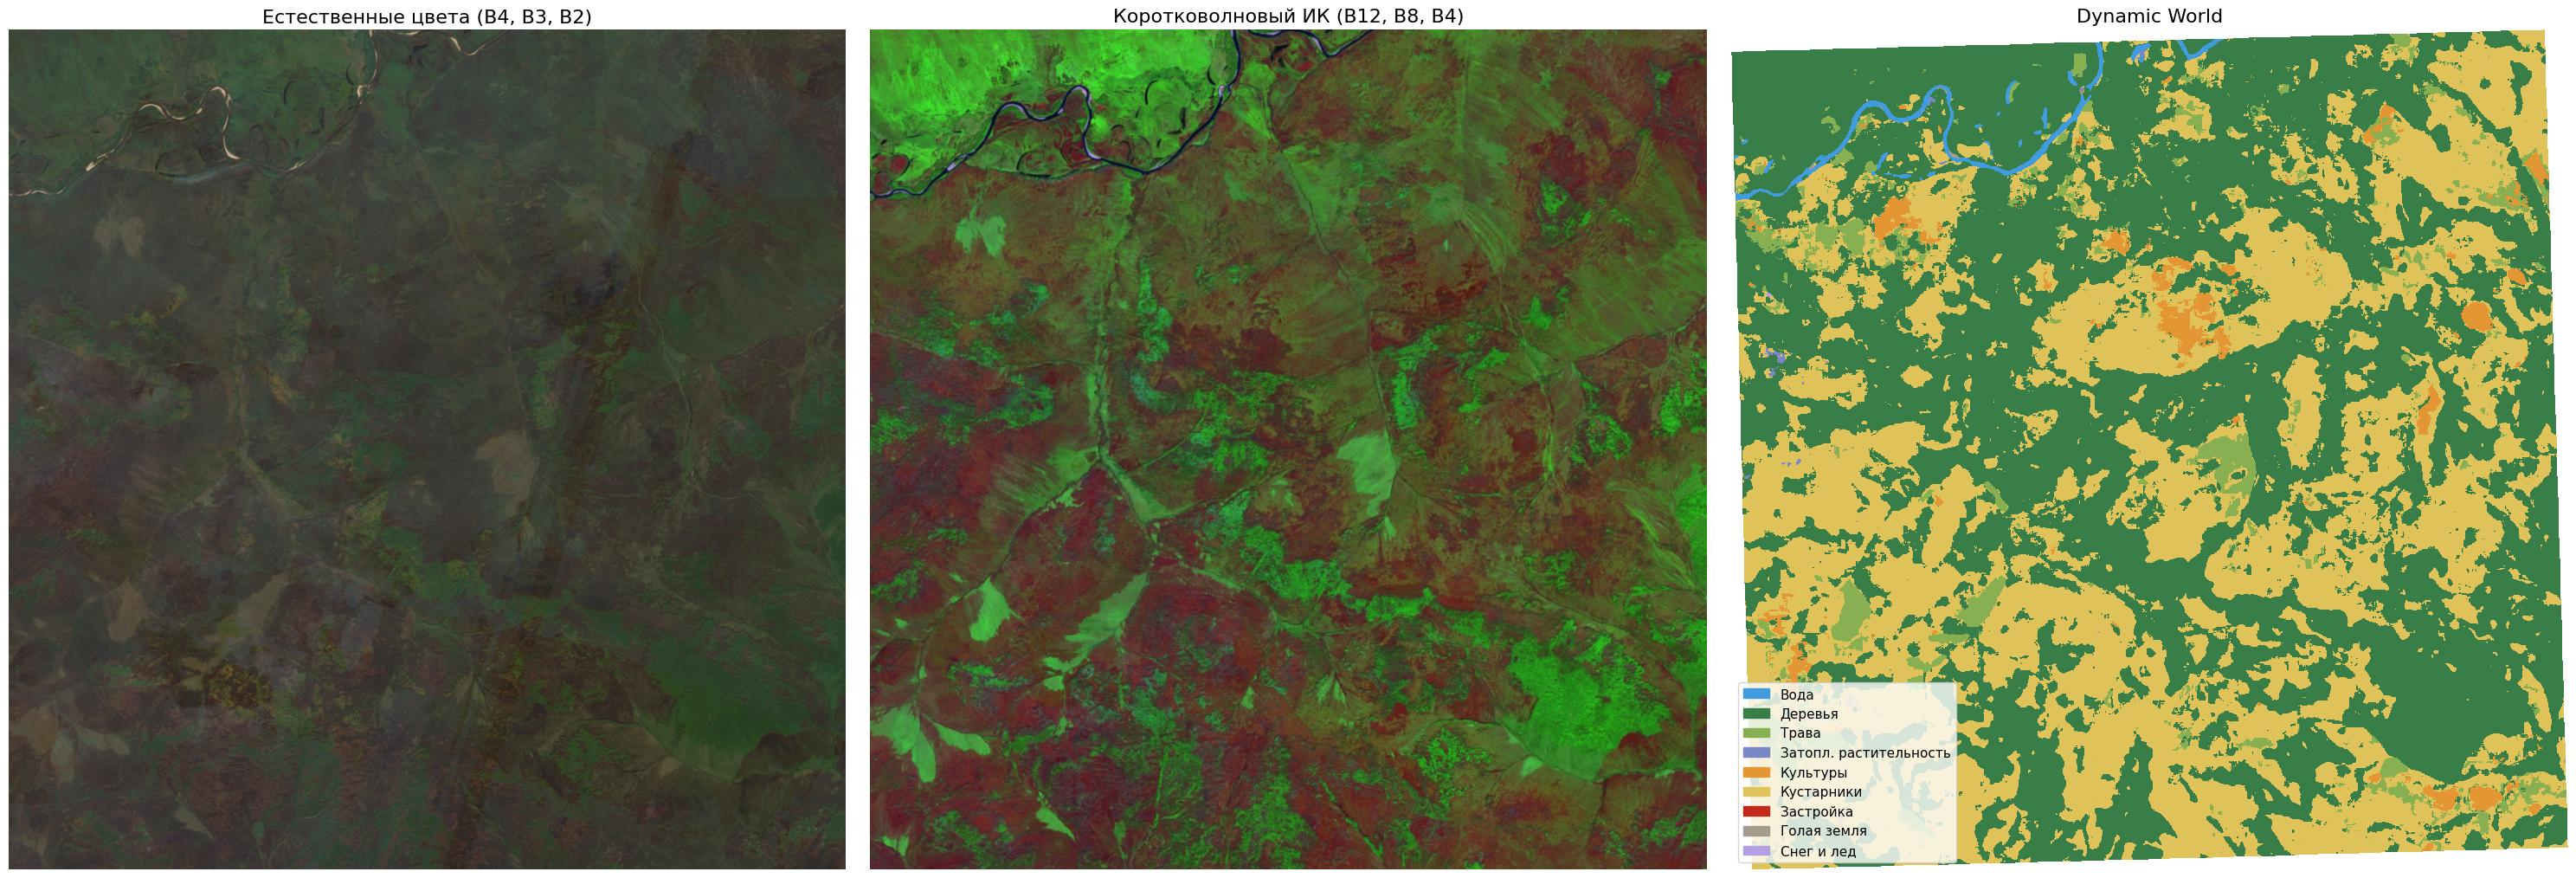

,"Площадь, га"
Деревья,10280.2
Кустарники,8099.5
Трава,766.5
Культуры,317.3
Вода,110.6
Голая земля,11.9
Затопл. растительность,9.8
Снег и лед,0.7


In [14]:
#@title Готовая функция: снимок в естественных цветах и в комбинации B12-B8-B4
def stretch(x, high):
    """Линейное растяжение значений отражения в диапазон 0-1."""
    return np.clip(np.nan_to_num(x, nan=0, posinf=0, neginf=0) / high, 0, 1)

rgb = stretch(np.dstack([bands[2], bands[1], bands[0]]), 0.3) ** (1 / 1.4)   # B4, B3, B2
swir = np.dstack([stretch(bands[5], 0.4), stretch(bands[3], 0.45), stretch(bands[2], 0.25)])   # B12, B8, B4
dw_cmap = ListedColormap(DW_COLORS)
dw_legend = [Patch(color=col, label=name) for col, name in zip(DW_COLORS, DW_NAMES)]

fig, axes = plt.subplots(1, 3, figsize=(30, 10))
axes[0].imshow(rgb)
axes[0].set_title('Естественные цвета (B4, B3, B2)', fontsize=16)
axes[1].imshow(swir)
axes[1].set_title('Коротковолновый ИК (B12, B8, B4)', fontsize=16)
axes[2].imshow(np.ma.masked_less(dw, 0), cmap=dw_cmap, vmin=-0.5, vmax=8.5, interpolation='nearest')
axes[2].set_title('Dynamic World', fontsize=16)
axes[2].legend(handles=dw_legend, loc='lower left', fontsize=11)
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

dw_areas = pd.Series(np.bincount(dw[valid], minlength=9) * PIXEL_AREA_HA, index=DW_NAMES, name='Площадь, га')
dw_areas[dw_areas > 0].sort_values(ascending=False).round(1)

**Задание 3.5 (продолжение).** Сравните три изображения. Запишите гипотезы: какие участки выглядят необычно на комбинации B12–B8–B4, хотя на снимке в естественных цветах не выделяются (или наоборот), и к какому классу Dynamic World их отнёс. Гипотезы проверите в разделе 5.

#### **Таблица 2. Гипотезы до анализа**

| № | Наблюдение (где, как выглядит в естественных цветах и в B12–B8–B4) | Класс Dynamic World | Гипотеза: что это за объект | Как проверить |
|---|---|---|---|---|
| 1 | ... | ... | ... | ... |
| 2 | ... | ... | ... | ... |
| 3 | ... | ... | ... | ... |

<details>
<summary><b>Пример формулировки</b></summary>

*Условный пример:* «В центре — светлое пятно неправильной формы около 2×3 км, в естественных цветах серо-бежевое, в B12–B8–B4 сиреневое, вокруг ярко-зелёная тайга. Dynamic World относит его к кустарникам и голой земле. Гипотеза: карьер и отвалы пустой породы. Проверка: отдельный кластер со спектром без растительности и высоким отражением в B11–B12».

</details>


| № | Наблюдение (где, как выглядит в естественных цветах и в B12–B8–B4) | Класс Dynamic World | Гипотеза: что это за объект | Как проверить |
| :-: | :--- | :--- | :--- | :--- |
| **1** | Внутри леса. Правильные геометрические контуры (квадраты, прямоугольники или что-то похожее на них). В RGB светло-зелёные или желтоватые. В B12–B8–B4 розовато-оранжевые или ярко-зелёные. | Деревья или кустарники | Вырубка леса | Проверить космоснимки высокого разрешения и поискать подъездные грунтовые дороги к этому участку. |
| **2** | На самых вершинах холмов или хребтов. В RGB серые зернистые текстуры, иногда с белыми пятнами. В B12–B8–B4 — сине-голубые или тёмно-синие скалы. | Затопленная растительность, снег и лёд, деревья | Может, мини-гора какая-то или вечная мерзлота (не знаю честно) | Проверить космоснимки высокого разрешения. |
| **3** | Извилистые узкие линии. В RGB тёмно-синие или чёрные. В B12–B8–B4 глубокий чёрный или тёмно-синий цвет. | Вода и затопленная растительность | Горная река или мини-болото | Проверить космоснимки высокого разрешения, посмотреть на специальных картах с водной гидрографией. |


---

## **4. Классификация с учителем по разметке Dynamic World**

В лекции классификаторы обучались по карте ESA WorldCover. Здесь разметкой будет Dynamic World: классификатор учится по спектру пикселя предсказывать класс, который поставил бы Dynamic World. Это удобно — разметку не нужно создавать вручную, — но у такого подхода есть пределы: модель повторит и классы, и ошибки разметки. Их мы и увидим.

### **4.1. Стратифицированная обучающая выборка**

Классы на территории занимают очень разную площадь: например, тайга — десятки квадратных километров, застройка — несколько гектаров. Простая случайная выборка (`sample`) почти не содержит точек редких классов, и модель их не выучит. **Стратифицированная выборка** (`stratifiedSample`) берёт заданное число точек из каждого класса: если пикселей класса меньше, берутся все.

**Параметры метода `stratifiedSample`:**
- `numPoints` — число точек на класс
- `classBand` — канал с метками классов
- `region`, `scale` — область и размер пикселя выборки
- `seed` — начальное значение генератора для воспроизводимости
- `tileScale` — дробление вычислений на более мелкие плитки (помогает избежать ошибки нехватки памяти)

К каждой точке сразу добавим номер блока «шахматной доски» со стороной 1 км — он понадобится для пространственной проверки в разделе 4.2.

In [15]:
# Номер блока шахматной доски 1×1 км: 0 — «чёрные» клетки, 1 — «белые»
BLOCK_SIZE = 1000
blocks = (ee.Image.pixelCoordinates(ee.Projection(utm_crs(roi)))
          .divide(BLOCK_SIZE).floor().reduce('sum').mod(2).toInt().rename('block'))

**Задание 4.1.** Получите выборку `samples`: по 400 точек каждого класса из изображения `composite.addBands(dynamic_world).addBands(blocks)` (`scale=SCALE`, `projection=utm_crs(roi)`, `seed=42`, `tileScale=4`). Проекция UTM обязательна: по умолчанию выборка берётся в географических координатах, где пиксель «10 м» по долготе в высоких широтах вдвое уже, и точки редких классов дублируются. Выведите число точек по классам (`aggregate_histogram('class')`) с названиями классов. Классы, у которых меньше 100 точек, исключите из выборки (`ee.Filter.inList`): по нескольким десяткам точек нельзя ни обучить, ни проверить модель. Список оставшихся кодов классов сохраните в `CLASSES`.

In [16]:
img_samples = composite.addBands(dynamic_world).addBands(blocks)

samples = img_samples.stratifiedSample(
    numPoints=400,
    classBand='class',
    region=roi,
    scale=SCALE,
    projection=utm_crs(roi),
    seed=42,
    tileScale=4
)

class_counts = samples.aggregate_histogram('class').getInfo()
print('Точки по классам:', class_counts)

class_map = {0: 'Вода', 1: 'Деревья', 2: 'Трава', 3: 'Затопл. растительность',
             4: 'Культуры', 5: 'Кустарники', 6: 'Застройка', 7: 'Голая земля', 8: 'Снег и лед'}

valid_classes = [code for code in class_map
                 if str(code) in class_counts and class_counts[str(code)] >= 100]
CLASSES = valid_classes
print('Классы для обучения (>= 100 точек):', CLASSES)

samples = samples.filter(ee.Filter.inList('class', CLASSES))

Точки по классам: {'0': 400, '1': 400, '2': 400, '3': 400, '4': 400, '5': 400, '7': 400, '8': 66}
Классы для обучения (>= 100 точек): [0, 1, 2, 3, 4, 5, 7]


### **4.2. Случайная и пространственная проверка точности**

В лекции выборка делилась на обучающую и проверочную случайно (70/30). Но соседние пиксели снимка почти одинаковы: если один пиксель поля попал в обучение, а соседний — в проверку, модель «узнаёт» знакомое место, а не применяет выученное правило. Точность на такой проверке завышена. Честнее проверять модель на **других участках** территории: обучать на «чёрных» клетках шахматной доски, а проверять на «белых». Так оценивают, как модель поведёт себя на новом месте.

**Задание 4.2.** Создайте два разбиения выборки:
- случайное: `randomColumn('random', 42)`, обучение — `random < 0.7`, проверка — остальные;
- пространственное: обучение — `block == 0`, проверка — `block == 1`.

Для каждого разбиения обучите `ee.Classifier.smileRandomForest(numberOfTrees=100, seed=42)` на признаках `FEATURES` и рассчитайте общую точность и каппу на проверочной части. Сохраните разбиения в словарь `splits = {'Случайная': (train, test), 'Пространственная': (train, test)}` и выведите таблицу результатов.

> 📚 **Подсказка:** [лекция по GEE](https://colab.research.google.com/drive/1BU-Q4D0XEIy2KiEtzw-3dKISE0lwGLV2), **раздел 4.2** (разделение по `randomColumn`) и **4.3** (`train`, `classify`, `errorMatrix`).

In [17]:
samples_rand = samples.randomColumn('random', 42)
train_rand = samples_rand.filter(ee.Filter.lt('random', 0.7))
test_rand = samples_rand.filter(ee.Filter.gte('random', 0.7))

train_spat = samples.filter(ee.Filter.eq('block', 0))
test_spat = samples.filter(ee.Filter.eq('block', 1))

def evaluate_classifier(train, test):
    classifier = ee.Classifier.smileRandomForest(numberOfTrees=100, seed=42).train(
        features=train,
        classProperty='class',
        inputProperties=FEATURES.getInfo()
    )
    classified = test.classify(classifier)
    return classified.errorMatrix('class', 'classification')


acc_rand = evaluate_classifier(train_rand, test_rand)
acc_spat = evaluate_classifier(train_spat, test_spat)

def parse_accuracy(matrix):
    accuracy = matrix.accuracy().getInfo()
    kappa = matrix.kappa().getInfo()
    return {'accuracy': accuracy, 'kappa': kappa}


results_acc = {}
for name, mat in [('Случайная', acc_rand), ('Пространственная', acc_spat)]:
    r = parse_accuracy(mat)
    results_acc[name] = r
    print(f'{name}: accuracy={r["accuracy"]:.4f}, kappa={r["kappa"]:.4f}')

splits = {'Случайная': (train_rand, test_rand), 'Пространственная': (train_spat, test_spat)}

Случайная: accuracy=0.7348, kappa=0.6700
Пространственная: accuracy=0.6680, kappa=0.6114


**Вопрос:** На сколько различаются точность и каппа случайного леса при случайной и пространственной проверке? Почему? Какой оценке вы бы доверяли, если модель нужно применить к соседнему участку тайги или к другому месторождению?

**Ответ:**

Разница в точности (Accuracy): Снижается на 0.0668 падая с 0.7348 до 0.6680.

Разница в каппе (Kappa): Снижается на 0.0791 падая с 0.6905 до 0.6114.

При случайной, модель так сказать подсматривает правильный ответ, поскольку в тест попадают пиксели, которые находятся вплотную к пикселям из обучения. И рузельтаты получаются супер пупер, оптимистичные.

При пространственной, тестовая выборка формируется из изолтированных блоков, которые модели не видела при обучении и поэтому более реально показывает способность модели.

доверил бы пространственной оценке

### **4.3. Сравнение классификаторов**

**Задание 4.3.** Выберите не менее трёх классификаторов из лекции (раздел 4.3) и сравните их **на пространственном разбиении**. Наивный байесовский классификатор не берите: он рассчитан на неотрицательные целые признаки (счётчики), а у нас дробные отражения и индексы. Сохраните обученные модели в словарь `models`, матрицы ошибок — в `matrices`, таблицу точности и каппы — в `metrics`, название лучшей модели по каппе — в `best_name`.

In [18]:
classifiers = {
    'Random Forest': ee.Classifier.smileRandomForest(numberOfTrees=100, seed=42),
    'SVM': ee.Classifier.libsvm(kernelType='RBF', cost=10),
    'Naive Bayes': ee.Classifier.smileNaiveBayes()
}


models = {}
matrices = {}
metrics = {}

train_spat, test_spat = splits['Пространственная']

for name, clf in classifiers.items():
    trained = clf.train(
        features=train_spat,
        classProperty='class',
        inputProperties=FEATURES.getInfo()
    )

    classified = test_spat.classify(trained)
    error_mat = classified.errorMatrix('class', 'classification')
    acc_val = error_mat.accuracy().getInfo()
    kappa_val = error_mat.kappa().getInfo()

    models[name] = trained
    matrices[name] = error_mat
    metrics[name] = {'accuracy': acc_val, 'kappa': kappa_val}

    print(f'{name}: accuracy={acc_val:.4f}, kappa={kappa_val:.4f}')

best_name = max(metrics, key=lambda k: metrics[k]['kappa'])
print('\nЛучшая модель:', best_name)


Random Forest: accuracy=0.6680, kappa=0.6114
SVM: accuracy=0.2133, kappa=0.1065
Naive Bayes: accuracy=0.1042, kappa=0.0000

Лучшая модель: Random Forest


### **4.4. Точность по классам**

Общая точность скрывает, какие классы модель путает. Для каждого класса считают две точности:

- **точность производителя** (`producersAccuracy`, она же полнота) — какая доля пикселей класса в разметке распознана моделью правильно; низкое значение означает, что модель **пропускает** класс;
- **точность пользователя** (`consumersAccuracy`, она же точность в смысле precision) — какая доля пикселей, отнесённых моделью к классу, действительно относится к нему; низкое значение означает, что модель **приписывает** классу чужие пиксели.

*Условный пример:* если из 100 пикселей «Застройки» модель нашла 60, точность производителя 0,6; если при этом она назвала «Застройкой» 80 пикселей и 60 из них верны, точность пользователя 0,75.

**Задание 4.4.** Для лучшей модели постройте таблицу `per_class`: название класса, точность производителя и точность пользователя для классов из `CLASSES`. Матрица ошибок GEE индексируется кодами классов, поэтому строка `producersAccuracy()` — это список длиной «максимальный код + 1». Постройте также тепловую карту матрицы ошибок, нормированной по строкам (истинным классам).

Точность по классам:
                    Класс  Производитель  Пользователь
0                    Вода       0.854305      0.724719
1                 Деревья       0.000000      0.000000
2                   Трава       0.000000      0.000000
3  Затопл. растительность       0.000000      0.000000
4                Культуры       0.000000      0.000000
5              Кустарники       0.000000      0.000000
6             Голая земля       0.000000      0.000000


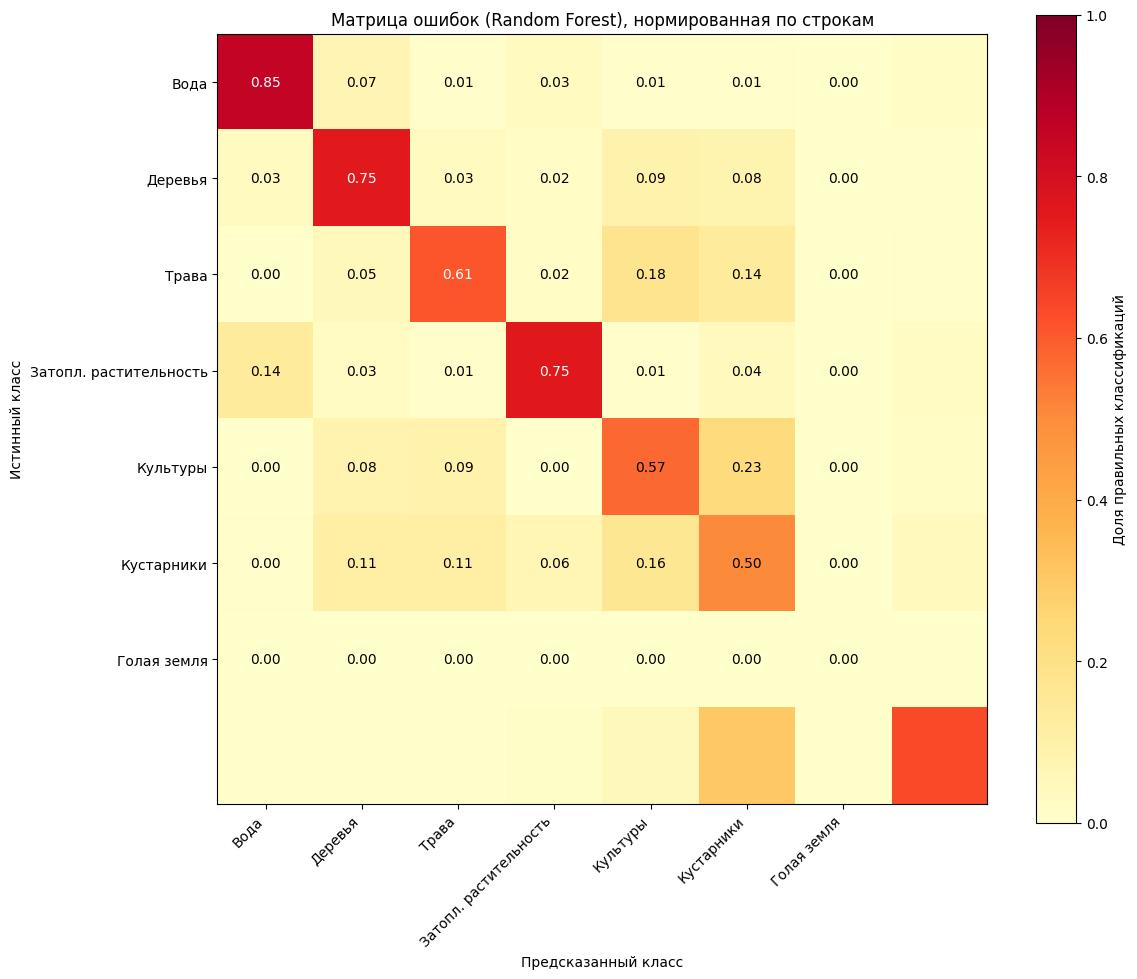

In [19]:
matrix_info = matrices[best_name].getInfo()
producers_info = matrices[best_name].producersAccuracy().getInfo()
consumers_info = matrices[best_name].consumersAccuracy().getInfo()

per_class = []
for idx, cls_code in enumerate(CLASSES):
    try:
        producers = producers_info[0][idx] if isinstance(producers_info[0], list) else producers_info[idx][0]
    except:
        producers = 0

    try:
        consumers = consumers_info[idx][0] if isinstance(consumers_info[idx], list) else consumers_info[0][idx]
    except:
        consumers = 0

    per_class.append({
        'Класс': class_map.get(cls_code, f'Класс {cls_code}'),
        'Производитель': producers,
        'Пользователь': consumers
    })

per_class_df = pd.DataFrame(per_class)
print("Точность по классам:")
print(per_class_df)

matrix_np = np.array(matrix_info)
row_sums = matrix_np.sum(axis=1)
with np.errstate(divide='ignore', invalid='ignore'):
    norm_matrix = np.where(row_sums[:, None] > 0, matrix_np / row_sums[:, None], 0)
plt.figure(figsize=(12, 10))
plt.imshow(norm_matrix, cmap='YlOrRd', vmin=0, vmax=1)
plt.colorbar(label='Доля правильных классификаций')

tick_labels = [class_map.get(c, str(c)) for c in CLASSES]
plt.xticks(range(len(CLASSES)), tick_labels, rotation=45, ha='right')
plt.yticks(range(len(CLASSES)), tick_labels)

for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        plt.text(j, i, f'{norm_matrix[i, j]:.2f}', ha='center', va='center',
                 color='black' if norm_matrix[i, j] < 0.6 else 'white', fontsize=10)

plt.title(f'Матрица ошибок ({best_name}), нормированная по строкам')
plt.xlabel('Предсказанный класс')
plt.ylabel('Истинный класс')
plt.tight_layout()
plt.show()


**Вопрос:** Какие классы модель распознаёт лучше всего и хуже всего? С какими классами путается самый проблемный класс? Объясните, почему спектрально эти классы похожи.

**Ответ:**

Лучше всего распознаёт воду 0.85 и затопленная растительность с деревьями по 0.75

Хуже всего кустарники 0.5 и культуры 0.57

Самый проблемный класс кустарники с точностью 0.5, путает с культурами и деревьями и травой

Всё зелённое, поэтому путает. Ну либо это связано с тем что это забайкалье и культуры там не распространены.

### **4.5. Важность признаков**

Случайный лес оценивает, насколько каждый признак помогает разделять классы. В GEE оценки возвращает метод `explain()` обученной модели (ключ `importance`).

**Задание 4.5.** Получите важность признаков модели `models['Random Forest']`, переведите её в доли от суммы и постройте горизонтальную столбчатую диаграмму, отсортированную по убыванию важности.

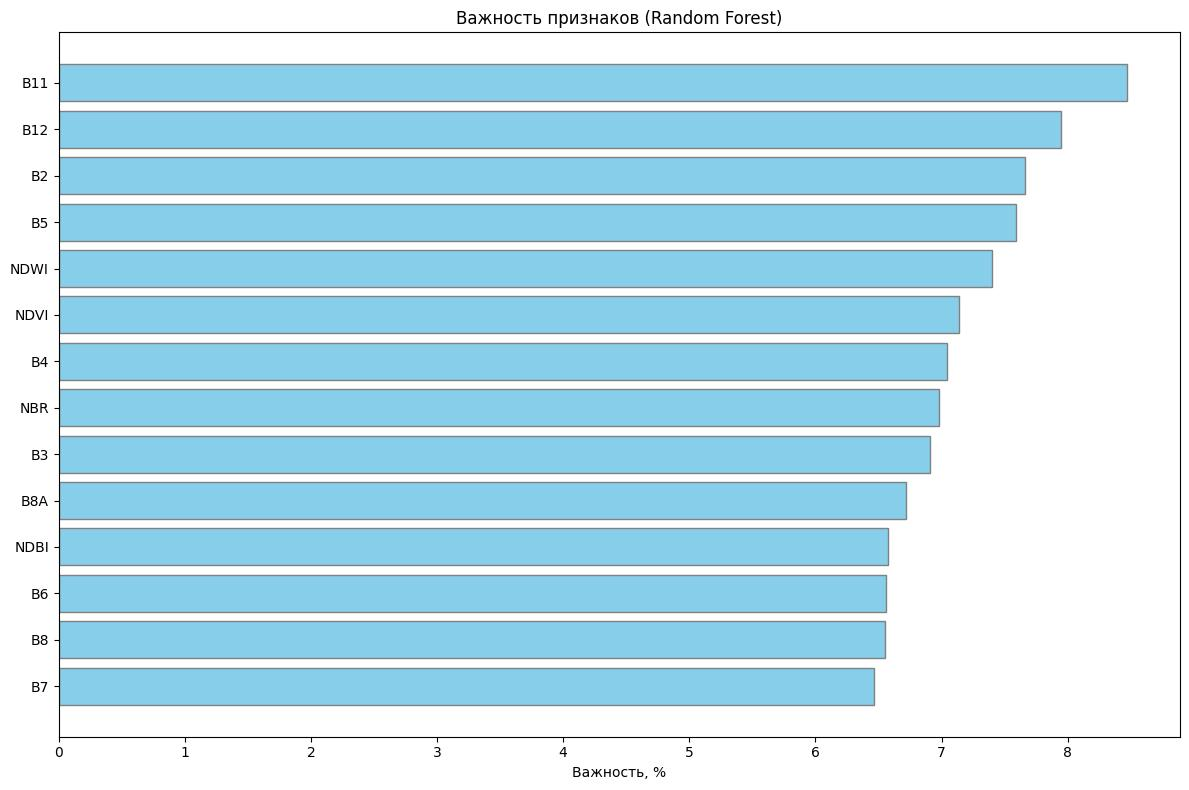

Доля важности ИК-каналов и индексов: 71.40%


In [20]:
rf_model = models['Random Forest']
importance_dict = rf_model.explain().getInfo()['importance']
feat_names = list(importance_dict.keys())
importance_values = np.array(list(importance_dict.values()), dtype=float)

total = importance_values.sum()
importance_pct = (importance_values / total) * 100 if total > 0 else importance_values

sorted_idx = np.argsort(-importance_pct)
sorted_names = [feat_names[i] for i in sorted_idx]
sorted_imp = importance_pct[sorted_idx]

plt.figure(figsize=(12, 8))
plt.barh(range(len(sorted_names)), sorted_imp, color='skyblue', edgecolor='gray')
plt.yticks(range(len(sorted_names)), sorted_names)
plt.xlabel('Важность, %')
plt.title('Важность признаков (Random Forest)')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

ir_features = ['B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12', 'NDVI', 'NDWI', 'NDBI']
ir_importance = sum(importance_dict[f] / total * 100 for f in ir_features if f in importance_dict)
print(f'Доля важности ИК-каналов и индексов: {ir_importance:.2f}%')


**Вопрос:** Какие три признака наиболее важны? Какую долю важности дают инфракрасные каналы (B8, B8A, B11, B12) вместе с индексами, использующими их? Что это говорит о пользе каналов за пределами видимого диапазона?

**Ответ:**
B11 B12 B2, ДОЛЯ 71.4%

Доказывает что имеет супер пупер важность ИК

### **4.6. Карта классификации и сравнение с Dynamic World**

Для построения итоговой карты обучим лучшую модель заново **на всей выборке** (обучающей и проверочной частях): проверка уже выполнена, и лишние точки сделают модель только точнее.

**Задание 4.6.** Обучите классификатор `best_name` на всей выборке `samples`, классифицируйте `composite.select(FEATURES)`, экспортируйте карту в `data/classification.tif` (тип `int16`) и загрузите её в массив `classification`. Рассчитайте:
- долю пикселей, в которых классификация совпадает с Dynamic World;
- таблицу `areas`: площадь каждого класса по Dynamic World и по своей карте (га);
- маску несовпадений и покажите её на снимке рядом с обеими картами.

  0%|          |0/36 tiles [00:00<?]

Доля совпадений: 58.63%
                        Dynamic World  Моя карта
Вода                           110.65     584.96
Деревья                      10280.20    7201.51
Трава                          766.51    1870.12
Затопл. растительность           9.84     915.90
Культуры                       317.26    2847.62
Кустарники                    8099.52    5488.50
Застройка                        0.00       0.00
Голая земля                     11.88     687.91
Снег и лед                       0.66       0.00


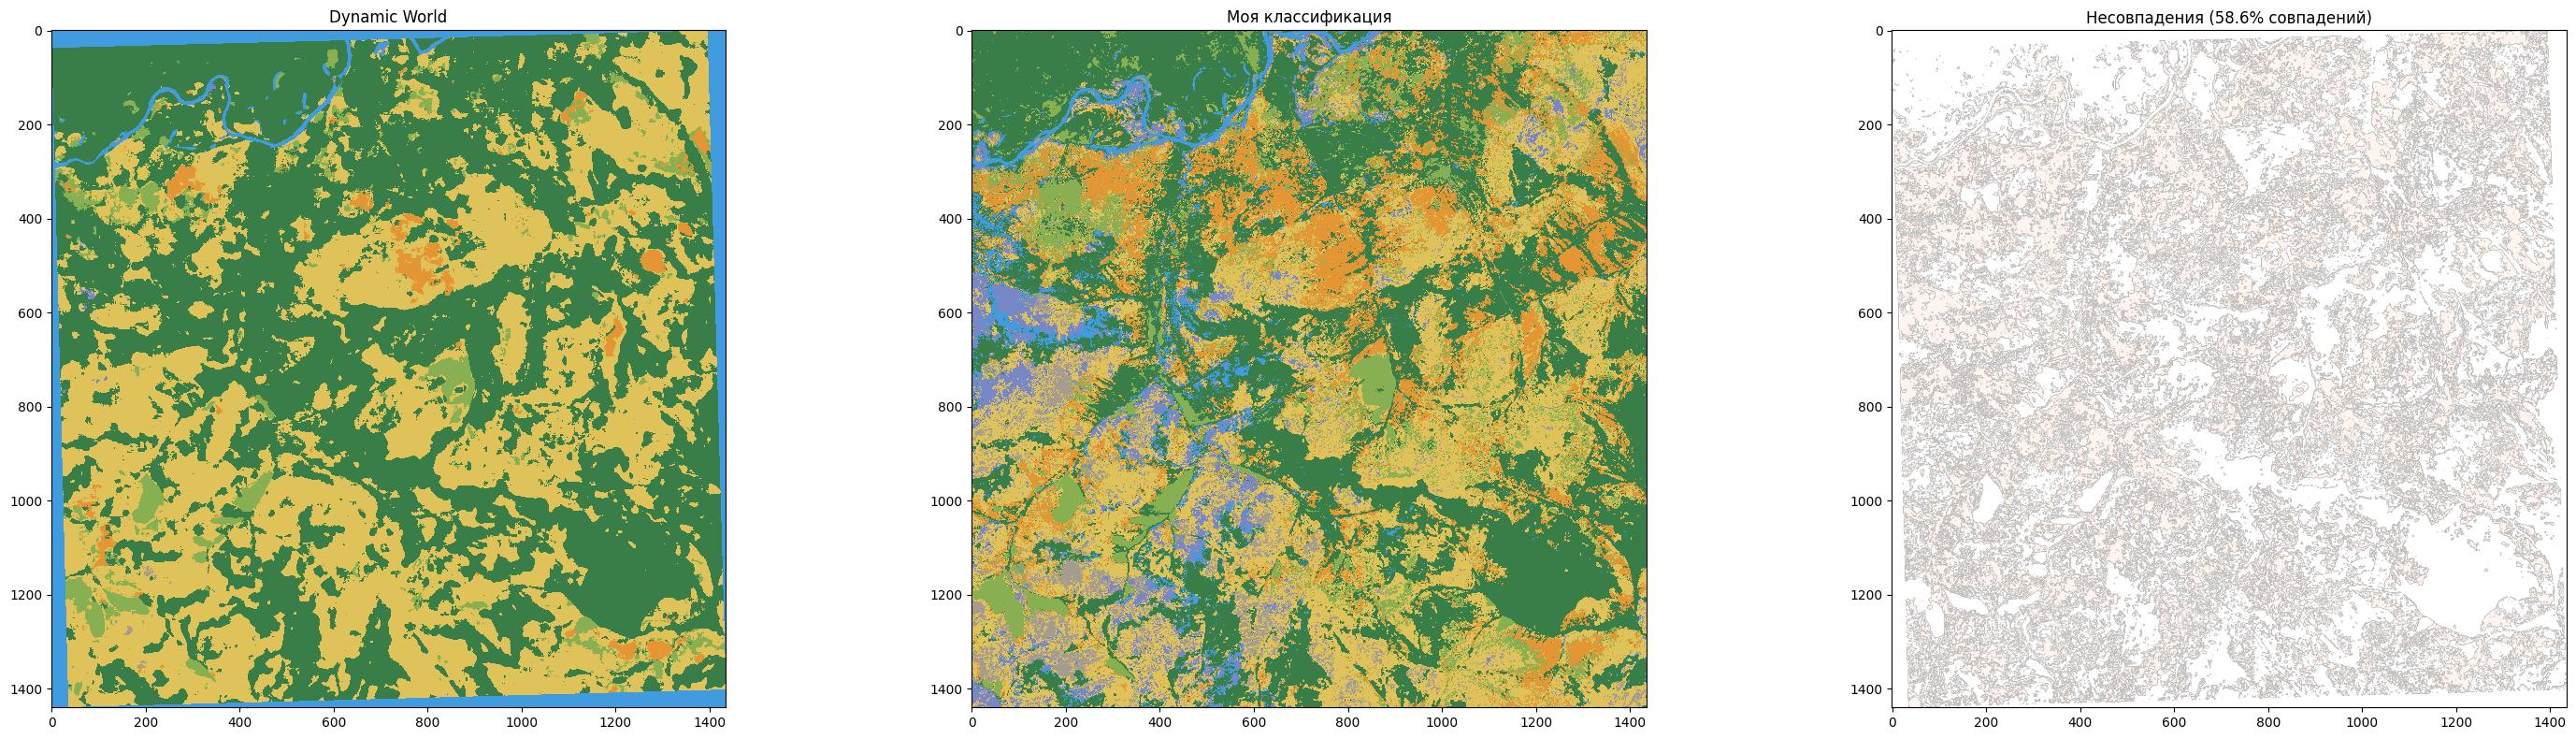

In [21]:
if best_name == 'Random Forest':
    final_clf = ee.Classifier.smileRandomForest(numberOfTrees=100, seed=42)
elif best_name == 'SVM':
    final_clf = ee.Classifier.libsvm(kernelType='RBF', cost=10)
else:
    final_clf = ee.Classifier.smileNaiveBayes()

best_classifier = final_clf.train(
    features=samples,
    classProperty='class',
    inputProperties=FEATURES.getInfo()
)

classification_img = composite.select(FEATURES).classify(best_classifier)

export_georeferenced_raster(
    classification_img, roi, 'data/classification.tif',
    scale=SCALE, dtype='int16'
)

classification = read_raster('data/classification.tif').squeeze()

match = (classification == dw) & valid
match_pct = match.sum() / valid.sum() * 100
print(f'Доля совпадений: {match_pct:.2f}%')

dw_areas = pd.Series(np.bincount(dw[valid], minlength=9) * PIXEL_AREA_HA, index=DW_NAMES, name='Dynamic World, га')
cls_areas = pd.Series(np.bincount(classification[valid], minlength=9) * PIXEL_AREA_HA, index=DW_NAMES, name='Моя карта, га')
areas = pd.DataFrame({'Dynamic World': dw_areas, 'Моя карта': cls_areas})
print(areas)

mismatch = (~match) & valid

fig, axes = plt.subplots(1, 3, figsize=(30, 8))
axes[0].imshow(dw, cmap=dw_cmap, vmin=-0.5, vmax=8.5, interpolation='nearest')
axes[0].set_title('Dynamic World')

axes[1].imshow(classification, cmap=dw_cmap, vmin=-0.5, vmax=8.5, interpolation='nearest')
axes[1].set_title('Моя классификация')

axes[2].imshow(np.ma.masked_where(mismatch == 0, mismatch), cmap='Reds')
axes[2].set_title(f'Несовпадения ({match_pct:.1f}% совпадений)')

plt.tight_layout()
plt.show()


**Вопрос:** Какова доля совпадения карт? Где сосредоточены несовпадения — на границах объектов, в каких-то конкретных типах местности? Площади каких классов различаются сильнее всего?

**Ответ:**

Доля 58.63% , несовпадения созредаточены по всей картинке, такие зернистые пятна серые.

Сильные отличия в деревьях разница  +3000 относительно моей карты
Сильные отличия в культурах разница -2800 относительно моей карты
Сильные отличия в затопленных землях -900 относительно моей карты
Сильные отличия в голой земле -650 относительно моей карты

### **4.7. Выводы по разделу 4**

Опишите, насколько точно модель воспроизводит Dynamic World при честной проверке, какие классы и признаки для неё важнее, и в чём главное ограничение обучения по готовой карте.

**Вывод:**

Хорошо воспроизводит воду и сомкнутые деревья. Проблемы возникают с кустарниками, травой, голой землёй.

Важные классы: деревья, голая земля, трава.

Важные признаки:B11, B12, B2

Обучение модели происходит не на реально поверхности, а на ошибках

---

## **5. Кластеризация в Google Earth Engine: поиск того, чего нет в легенде**

Классификатор умеет только то, чему его научили: каждому пикселю он присваивает один из классов разметки. Кластеризация не знает никаких классов и группирует пиксели по сходству спектра. Если на территории есть объекты, спектрально непохожие на всё остальное, они могут образовать собственный кластер — даже если в легенде для них нет класса и на снимке в естественных цветах они почти не видны.

### **5.1. Стандартизация признаков в GEE**

Кластеризовать будем по восьми признакам `LOCAL_BANDS`: шести каналам отражения и индексам NDVI и NDWI. Отражение меняется в пределах 0–0,6, а индексы — от −1 до 1, поэтому без масштабирования индексы определяли бы расстояния между пикселями сильнее каналов. Стандартизация приводит каждый признак к среднему 0 и стандартному отклонению 1: $z = (x - \mu) / \sigma$.

> 📚 **Подсказка:** лекция «Кластеризация спутниковых снимков в среде Google Earth Engine», **раздел 2.5** (масштабирование признаков); в GEE среднее и стандартное отклонение каналов по области даёт `image.reduceRegion(ee.Reducer.mean().combine(ee.Reducer.stdDev(), sharedInputs=True), region, scale=..., bestEffort=True)`, ключи результата — `B2_mean`, `B2_stdDev` и т. д.

**Задание 5.1.** Допишите функцию `standardize(image, region)`: она рассчитывает по области средние и стандартные отклонения всех каналов (`scale=30` — для оценки статистик этого достаточно), возвращает стандартизированное изображение и два списка — средние и стандартные отклонения в порядке каналов. Получите `cluster_input, means, stds`.

In [22]:
def standardize(image, region):
    """Стандартизация каналов изображения по статистикам области: (x - среднее) / стандартное отклонение."""
    names = image.bandNames().getInfo()
    stats = image.reduceRegion(
        ee.Reducer.mean().combine(ee.Reducer.stdDev(), sharedInputs=True),
        region, scale=30, bestEffort=True
    ).getInfo()
    means = [stats[f'{n}_mean'] for n in names]
    stds = [stats[f'{n}_stdDev'] for n in names]
    standardized = image.subtract(ee.Image.constant(means)).divide(ee.Image.constant(stds))
    standardized = standardized.rename(names)
    return standardized, means, stds

cluster_input, means, stds = standardize(composite.select(LOCAL_BANDS), roi)
print('Средние:', means)
print('Стд. отклонения:', stds)

Средние: [0.03230402619314365, 0.04289074277398725, 0.04147117764795894, 0.14603568944617396, 0.1640047739031202, 0.11617850687513075, 0.5255910007832997, -0.5233289495142113]
Стд. отклонения: [0.007029611981219157, 0.009099173599656764, 0.008150937065519144, 0.05554456086903312, 0.021937407379658217, 0.023127134118137934, 0.136199192568485, 0.09452791457481613]


### **5.2. K-средних на серверах GEE при разных K**

> 📚 **Подсказка:** лекция «Кластеризация спутниковых снимков в среде Google Earth Engine», **раздел 3.5** (`ee.Clusterer.wekaKMeans`, `train`, `cluster`).

Число кластеров заранее неизвестно. При малом $K$ редкие объекты «прилипают» к крупным кластерам, при большом — крупные однородные поверхности дробятся на части. Поэтому построим разбиения сразу для нескольких $K$ и сравним их.

**Задание 5.2.** Получите обучающую выборку `training` из `cluster_input` (10 000 пикселей, `scale=SCALE`, `projection=utm_crs(roi)`, `seed=42`, `tileScale=4`). Для `K_LIST = [6, 12, 18]` обучите `ee.Clusterer.wekaKMeans(nClusters=K, init=1, seed=42)` и кластеризуйте `cluster_input`. Объедините карты в одно изображение `clusters` с каналами `K6`, `K12`, `K18` (`ee.Image.cat`), покажите кластеры при $K = 12$ на интерактивной карте (`randomVisualizer()`) и экспортируйте `clusters` в `data/clusters.tif` (тип `int16`). Загрузите результат в массив `cluster_maps` (каналы — разные $K$).

In [23]:
K_LIST = [6, 12, 18]

training = cluster_input.sample(
    region=roi,
    numPixels=10000,
    scale=SCALE,
    projection=utm_crs(roi),
    seed=42,
    tileScale=4
)

clusterers = {}
cluster_maps_list = []
for K in K_LIST:
    clusterer = ee.Clusterer.wekaKMeans(nClusters=K, init=1, seed=42).train(training)
    clusterers[K] = clusterer
    clusters_K = cluster_input.cluster(clusterer)
    cluster_maps_list.append(clusters_K)

clusters = ee.Image.cat(cluster_maps_list).rename([f'K{K}' for K in K_LIST])

idx_12 = K_LIST.index(12)
K12_img = cluster_maps_list[idx_12]

m_cluster = geemap.Map(center=[LAT, LON], zoom=8)
m_cluster.add_basemap('Esri.WorldImagery')
m_cluster.add_layer(K12_img, {'min': 0, 'max': 11, 'palette': 'rainbow'}, 'Кластеры K=12')
m_cluster


export_georeferenced_raster(
    clusters, roi, 'data/clusters.tif',
    scale=SCALE, dtype='int16'
)

cluster_maps = read_raster('data/clusters.tif')
print(f'Форма cluster_maps: {cluster_maps.shape}')

  0%|          |0/108 tiles [00:00<?]

Форма cluster_maps: (3, 1440, 1435)


### **5.3. Площади и спектральные профили кластеров**

> 📚 **Подсказка:** лекция «Кластеризация спутниковых снимков в среде Google Earth Engine», **разделы 3.3–3.4** (спектральные профили, состав кластеров по Dynamic World).

Кроме профилей, оценим **необычность** каждого кластера — расстояние от его центроида до «среднего» пикселя территории в пространстве стандартизированных признаков. После стандартизации средний пиксель находится в начале координат, поэтому необычность — это просто длина вектора центроида: $\lVert c_k
Vert = \sqrt{\sum_j c_{kj}^2}$. Кластеры фоновых поверхностей, занимающих большую часть территории, лежат близко к среднему, а спектрально непохожие на фон группы — далеко от него, независимо от их площади. Центроиды кластеров GEE вычислим сами: это средние стандартизированные признаки пикселей каждого кластера.

**Задание 5.3.** Для разбиения с $K = 12$ (`labels = cluster_maps[1]`):
- стандартизируйте признаки пикселей `pixels` теми же `means` и `stds`, что и в GEE (массив `z`), и рассчитайте центроиды кластеров `centroids` (форма $(K, 8)$);
- постройте таблицу `profiles`: для каждого кластера — площадь (га), доля площади (%), необычность и средние значения восьми признаков `LOCAL_BANDS` (по массиву `bands`); отсортируйте её по площади;
- покажите карту кластеров рядом со снимком и график спектральных профилей шести каналов (по оси X — каналы, по оси Y — среднее отражение, по линии на кластер).

In [24]:
K = 12
labels = cluster_maps[K_LIST.index(K)]
cluster_colors = plt.cm.tab20(np.linspace(0, 1, 20))[:K]
cluster_cmap = ListedColormap(cluster_colors)

    Кластер  Площадь, га  Доля, %  Необычность     B2     B3     B4     B8  \
0        10      2679.83   13.675        1.105  0.662  0.415  0.369  0.079   
1         1      2332.98   11.905        1.724 -0.963 -1.003 -0.578 -0.498   
2         9      2192.98   11.191        1.585 -0.597 -0.195 -0.191  0.337   
3         3      2082.48   10.627        2.183 -0.594 -1.118 -0.435 -1.039   
4         5      1758.81    8.975        3.166  0.252 -0.669  0.215 -1.256   
5         4      1702.10    8.686        2.544  0.816  1.270  0.852  1.162   
6         6      1696.20    8.656        1.488  0.051 -0.110 -0.073 -0.483   
7        11      1675.68    8.551        1.846  0.758  0.077  0.700 -0.579   
8         2      1504.83    7.679        2.168 -0.372  0.337 -0.538  0.354   
9         7      1065.65    5.438        3.944 -0.820  0.739 -1.270  1.598   
10        8       851.90    4.347        4.454  1.129  1.957  0.970  2.670   
11        0        53.08    0.271        9.529  0.778  0.097  0.

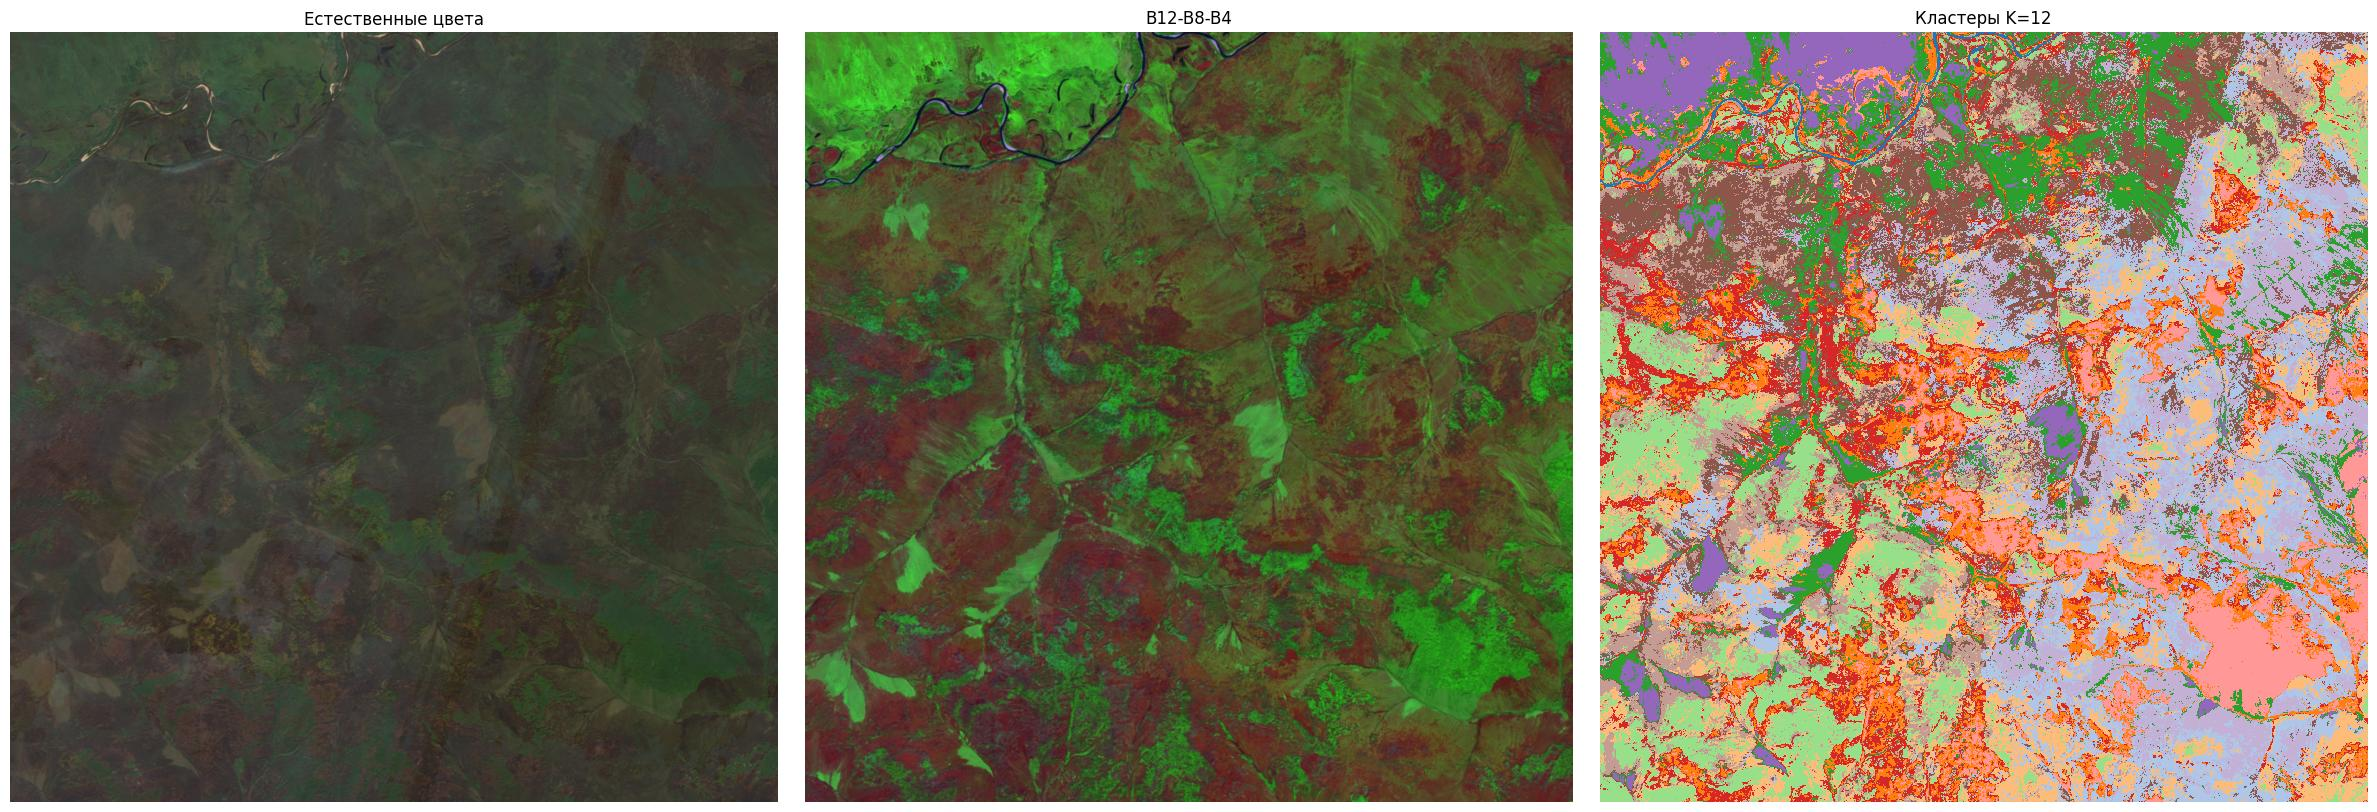

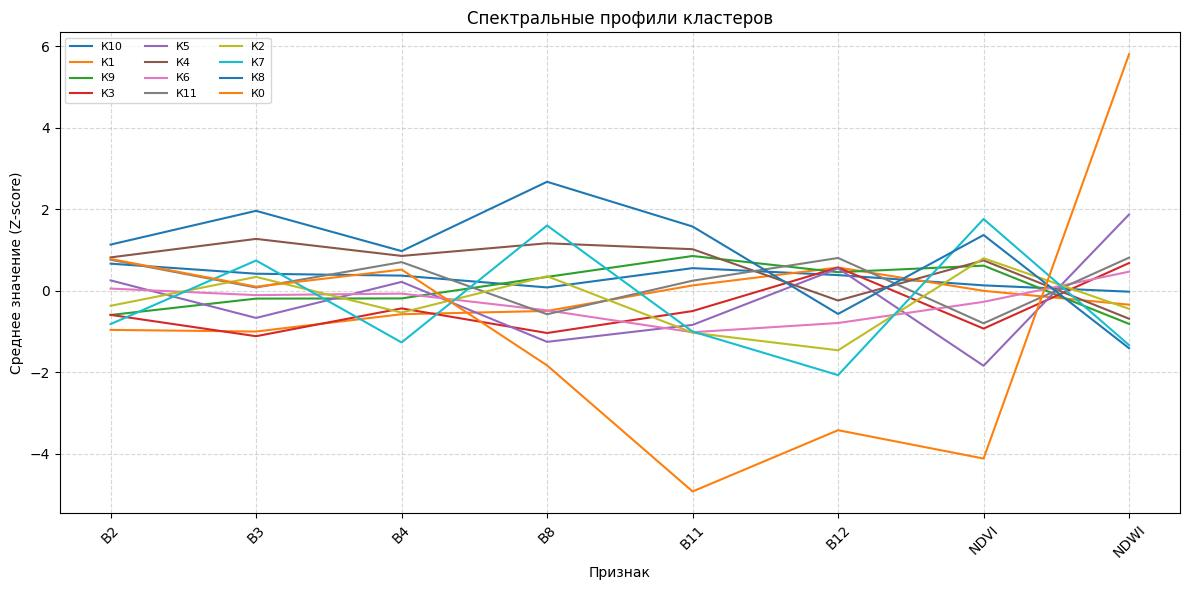

In [25]:
K = 12
idx_K = K_LIST.index(K)
labels = cluster_maps[idx_K]
cluster_colors = plt.cm.tab20(np.linspace(0, 1, 20))[:K]
cluster_cmap = ListedColormap(cluster_colors)

means_arr = np.array(means)[:, None, None]
stds_arr = np.array(stds)[:, None, None]

z_pixels = (bands[:len(LOCAL_BANDS)] - means_arr) / stds_arr
z = z_pixels.reshape(z_pixels.shape[0], -1).T

valid_flat = valid.ravel()
labels_flat = labels.ravel()

centroids = np.zeros((K, z.shape[1]))
for k in range(K):
    mask_k = (labels_flat == k) & valid_flat
    if mask_k.sum() > 0:
        centroids[k] = z[mask_k].mean(axis=0)

profiles = []
for k in range(K):
    mask_k = (labels_flat == k) & valid_flat
    area_ha = mask_k.sum() * PIXEL_AREA_HA
    pct = mask_k.sum() / valid_flat.sum() * 100
    unusualness = np.sqrt((centroids[k] ** 2).sum())
    if mask_k.sum() > 0:
        mean_feats = z[mask_k].mean(axis=0)
    else:
        mean_feats = np.zeros(len(LOCAL_BANDS))
    profiles.append({
        'Кластер': k,
        'Площадь, га': area_ha,
        'Доля, %': pct,
        'Необычность': unusualness,
        **{f: mean_feats[i] for i, f in enumerate(LOCAL_BANDS)}
    })

profiles_df = pd.DataFrame(profiles).sort_values('Площадь, га', ascending=False).reset_index(drop=True)
print(profiles_df.round(3))

try:
    fig, axes = plt.subplots(1, 3, figsize=(24, 8))
    axes[0].imshow(rgb)
    axes[0].set_title('Естественные цвета')
    axes[0].axis('off')
    axes[1].imshow(swir)
    axes[1].set_title('B12-B8-B4')
    axes[1].axis('off')
    axes[2].imshow(labels, cmap=cluster_cmap, interpolation='nearest')
    axes[2].set_title(f'Кластеры K={K}')
    axes[2].axis('off')
    plt.tight_layout()
    plt.show()
except NameError:
    print()

fig, ax = plt.subplots(figsize=(12, 6))
for idx in range(len(profiles_df)):
    row = profiles_df.iloc[idx]
    k_num = int(row['Кластер'])
    ax.plot(LOCAL_BANDS, row[LOCAL_BANDS].values, label=f'К{k_num}')

ax.set_xlabel('Признак')
ax.set_ylabel('Среднее значение (Z-score)')
ax.set_title('Спектральные профили кластеров')
ax.legend(fontsize=8, ncol=3)
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


### **5.4. Состав кластеров по Dynamic World и по своей классификации**

**Задание 5.4.** Постройте две таблицы сопряжённости, нормированные по строкам (%): кластер × класс Dynamic World (`dw`) и кластер × класс вашей классификации (`classification`). Строки упорядочите так же, как в `profiles` (по площади). Выведите их рядом в виде тепловых карт.

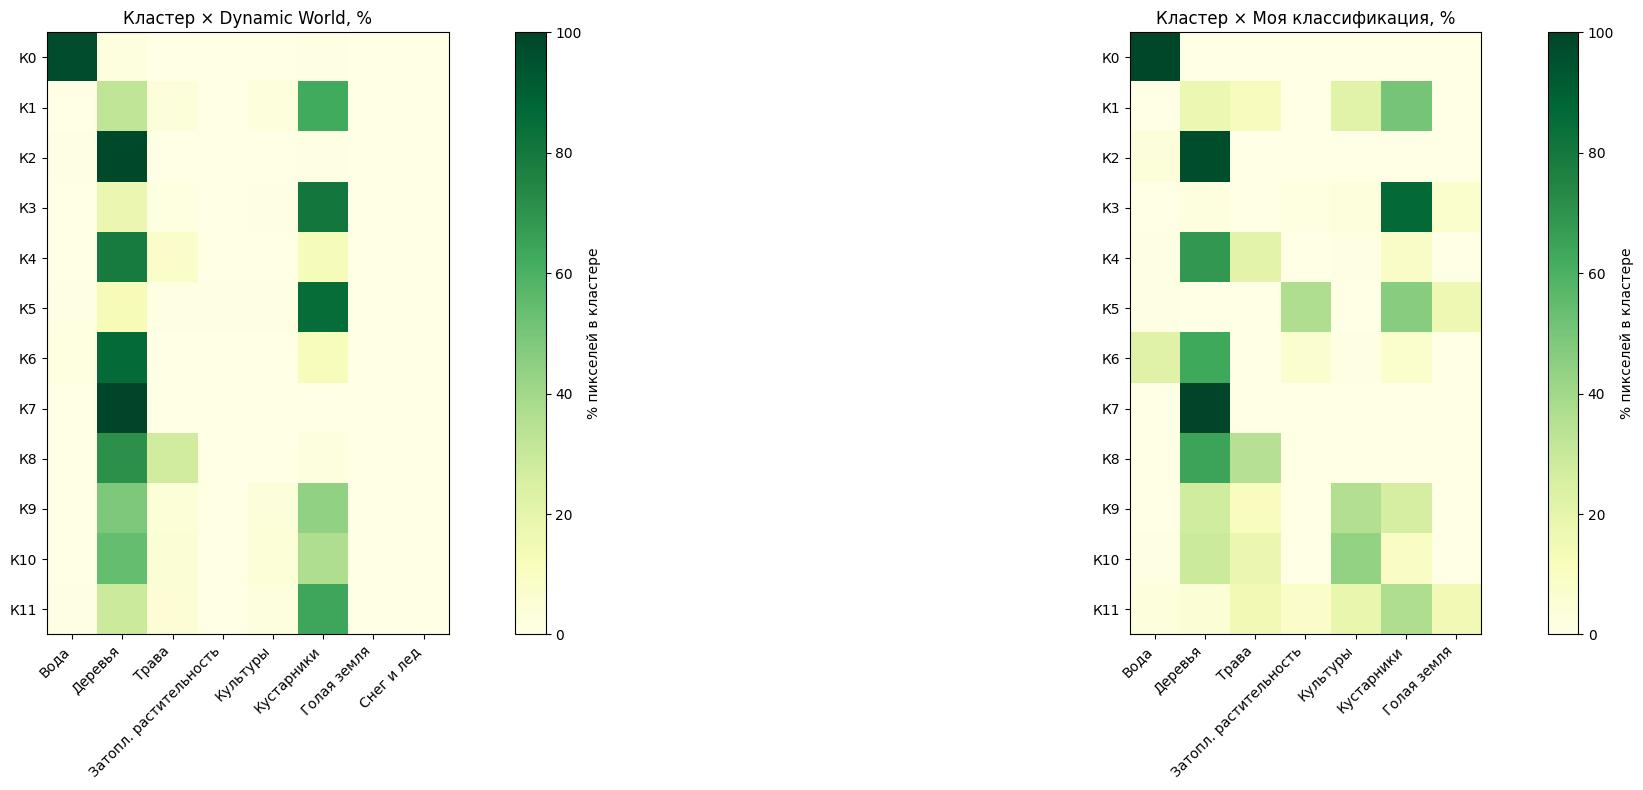

Состав кластеров по Dynamic World (доли):
            Вода  Деревья  Трава  Затопл. растительность  Культуры  \
Кластер 0   0.97     0.02   0.00                     0.0      0.00   
Кластер 1   0.00     0.32   0.03                     0.0      0.03   
Кластер 2   0.01     0.99   0.00                     0.0      0.00   
Кластер 3   0.00     0.18   0.01                     0.0      0.01   
Кластер 4   0.00     0.79   0.08                     0.0      0.00   
Кластер 5   0.01     0.13   0.01                     0.0      0.00   
Кластер 6   0.02     0.86   0.00                     0.0      0.00   
Кластер 7   0.00     1.00   0.00                     0.0      0.00   
Кластер 8   0.00     0.71   0.27                     0.0      0.00   
Кластер 9   0.00     0.49   0.04                     0.0      0.03   
Кластер 10  0.00     0.54   0.05                     0.0      0.04   
Кластер 11  0.01     0.29   0.05                     0.0      0.02   

            Кустарники  Голая земля  Снег и лед

In [26]:
dw_cross = pd.crosstab(labels[valid], dw[valid], normalize='index')
ordered_dw = [dw_cross.loc[k] for k in range(K) if k in dw_cross.index]
dw_cross_ordered = pd.DataFrame(ordered_dw).fillna(0)
dw_cross_ordered.columns = [class_map.get(c, str(c)) for c in dw_cross.columns]
dw_cross_ordered.index = [f'Кластер {i}' for i in dw_cross_ordered.index]

cls_cross = pd.crosstab(labels[valid], classification[valid], normalize='index')
ordered_cls = [cls_cross.loc[k] for k in range(K) if k in cls_cross.index]
cls_cross_ordered = pd.DataFrame(ordered_cls).fillna(0)
cls_cross_ordered.columns = [class_map.get(c, str(c)) for c in cls_cross.columns]
cls_cross_ordered.index = [f'Кластер {i}' for i in cls_cross_ordered.index]

fig, axes = plt.subplots(1, 2, figsize=(24, 8))

im1 = axes[0].imshow(dw_cross_ordered * 100, cmap='YlGn', vmin=0, vmax=100)
axes[0].set_title('Кластер × Dynamic World, %')
axes[0].set_xticks(range(len(dw_cross_ordered.columns)))
axes[0].set_xticklabels(dw_cross_ordered.columns, rotation=45, ha='right')
axes[0].set_yticks(range(len(dw_cross_ordered.index)))
axes[0].set_yticklabels([f'К{k}' for k in range(K)])
plt.colorbar(im1, ax=axes[0], label='% пикселей в кластере')

im2 = axes[1].imshow(cls_cross_ordered * 100, cmap='YlGn', vmin=0, vmax=100)
axes[1].set_title('Кластер × Моя классификация, %')
axes[1].set_xticks(range(len(cls_cross_ordered.columns)))
axes[1].set_xticklabels(cls_cross_ordered.columns, rotation=45, ha='right')
axes[1].set_yticks(range(len(cls_cross_ordered.index)))
axes[1].set_yticklabels([f'К{k}' for k in range(K)])
plt.colorbar(im2, ax=axes[1], label='% пикселей в кластере')

plt.tight_layout()
plt.show()

print('Состав кластеров по Dynamic World:')
print(dw_cross_ordered.round(2))
print('Состав кластеров по классификации:')
print(cls_cross_ordered.round(2))


**Задание 5.4 (продолжение).** По профилям, составу и виду на карте дайте названия всем кластерам и заполните таблицу. Названия — ваша интерпретация, а не результат алгоритма.

#### **Таблица 3. Интерпретация кластеров (K = 12)**

| Кластер | Площадь, га | Спектральный профиль | Состав по Dynamic World | Название |
|---|---|---|---|---|
| ... | ... | ... | ... | ... |

### Таблица 5.4. Интерпретация и названия кластеров (k-means)

| Кластер | Площадь, га | Спектральный профиль | Состав по Dynamic World | Название (Интерпретация) |
|---|---|---|---|---|
| Кластер 0 | 53.08 | Полное поглощение в ИК-диапазоне (B8, SWIR), провал спектра. | Вода (97%), Деревья (2%) | Открытые водные объекты (горные реки, глубокие озера) |
| Кластер 1 | 2332.98 | Отрицательные аномалии во всех каналах, пониженное отражение в видимом и NIR. | Кустарники (62%), Деревья (32%), Трава (3%) | Таёжное редколесье / Смешанные кустарниковые заросли |
| Кластер 2 | 1504.83 | Поглощение в Red (B4) и выраженный подъем в ИК (B8). | Деревья (99%), Вода (1%) | **Хвойная сомкнутая тайга (основа лесного массива)** |
| Кластер 3 | 2082.48 | Глубокое падение в ИК-каналах при умеренном отражении в видимом спектре. | Кустарники (80%), Деревья (18%) | Зарастающие гари / Склоны с доминированием кустарничков |
| Кластер 4 | 1702.10 | Максимальные положительные значения во всех базовых спектральных каналах. | Деревья (79%), Кустарники (13%), Трава (8%) | Осветленный лес / Склоновые разреженные леса |
| Кластер 5 | 1758.81 | Высокие значения в видимом синем (B2), жесткий провал в ближнем ИК (B8). | Кустарники (85%), Деревья (13%) | Заболоченные мари / Травяно-кустарничковые низинные болота |
| Кластер 6 | 1696.20 | Профиль смешанного пикселя, близкие к нулю аномалии в видимом диапазоне. | Деревья (86%), Кустарники (12%), Вода (2%) | Затененные склоны гор и Прирусловые леса |
| Кластер 7 | 1065.65 | Классический мощный пик вегетации в ИК (B8) и глубокое поглощение хлорофиллом в Red. | Деревья (100%) | Плотные коренные хвойные леса  |
| Кластер 8 | 851.90 | Максимальный экстремум в ИК (B8) и высокие значения в видимых каналах. | Деревья (71%), Трава (27%), Кустарники (2%) | Лесные поляны и Пойменные луга в долинах рек |
| Кластер 9| 2192.98 | Положительные аномалии в ИК при среднем уровне отражения в видимом спектре. | Деревья (49%), Кустарники (44%), Трава и Культуры | Молодые вырубки и Нарушенные участки лесозаготовок |
| Кластер 10 | 2679.83 | Самый крупный кластер. Повышенное отражение в видимом диапазоне, сильный дефицит ИК. | Деревья (54%), Кустарники (37%), ТраваиКультуры | Старые сухие гари / Участки гарей в стадии возобновления |
| Кластер 11 | 1675.68 | Высокий отклик в каналах B2 и B4 (видимый спектр), сильное поглощение в NIR. | Кустарники (64%), Деревья (29%), Трава (5%) | Каменистые россыпи (курумники) и Субальпийские гольцы вершин |


### **5.5. Необычные кластеры: «иголка в стоге сена»**

Первые кандидаты на интересные объекты — кластеры, далёкие от фона: алгоритм отвёл им собственный центроид, потому что их спектр не похож на спектр основной части территории. Часто это и самые маленькие кластеры, но не всегда: крупный карьер или большая гарь могут занимать сотни гектаров и всё же резко отличаться от окружающего леса, а несколько маленьких кластеров могут оказаться оттенками фона. Поэтому ориентируемся на необычность, а площадь учитываем при интерпретации.

In [27]:
#@title Готовая функция: фрагменты снимка с подсветкой пикселей маски
def zoom_views(mask, n=3, size=60, color=(1, 0, 0), title=''):
    """n фрагментов с наибольшей плотностью пикселей маски: снимок, B12-B8-B4 и подсветка."""
    step = 2 * size
    density = np.add.reduceat(np.add.reduceat(mask.astype(int), np.arange(0, H, step), axis=0), np.arange(0, W, step), axis=1)
    best = np.dstack(np.unravel_index(np.argsort(density.ravel())[::-1][:n], density.shape))[0]
    fig, axes = plt.subplots(3, n, figsize=(6 * n, 18))
    for j, (r, c) in enumerate(best):
        r = min(max(r * step + size, size), H - size)
        c = min(max(c * step + size, size), W - size)
        window = np.s_[r - size:r + size, c - size:c + size]
        highlight = rgb[window].copy()
        highlight[mask[window]] = color
        for i, img in enumerate([rgb[window], swir[window], highlight]):
            axes[i, j].imshow(img)
            axes[i, j].axis('off')
        axes[0, j].set_title(f'Фрагмент {j + 1}: строка {r}, столбец {c}')
    fig.suptitle(title, fontsize=16)
    plt.tight_layout()
    plt.show()

**Задание 5.5.** Выведите три кластера с наибольшей необычностью с площадью и двумя главными классами Dynamic World и покажите для каждого карту расположения пикселей на снимке и фрагменты крупным планом (`zoom_views(labels == k, title=...)`). Затем выберите кластеры, которые вы считаете «иголками» — объектами, не имеющими своего класса в Dynamic World, — и запишите их номера в список `NEEDLES`.

In [28]:
NEEDLES = [...]   # номера кластеров-«иголок»
needle_mask = np.isin(labels, NEEDLES) & valid
# Ваш код: площадь «иголок» и их состав по Dynamic World и по своей классификации, %

Три самых необычных кластера: [0, 8, 7]
  Кластер 0: площадь=53.1 га, необычность=9.529
  Кластер 8: площадь=851.9 га, необычность=4.454
  Кластер 7: площадь=1065.7 га, необычность=3.944


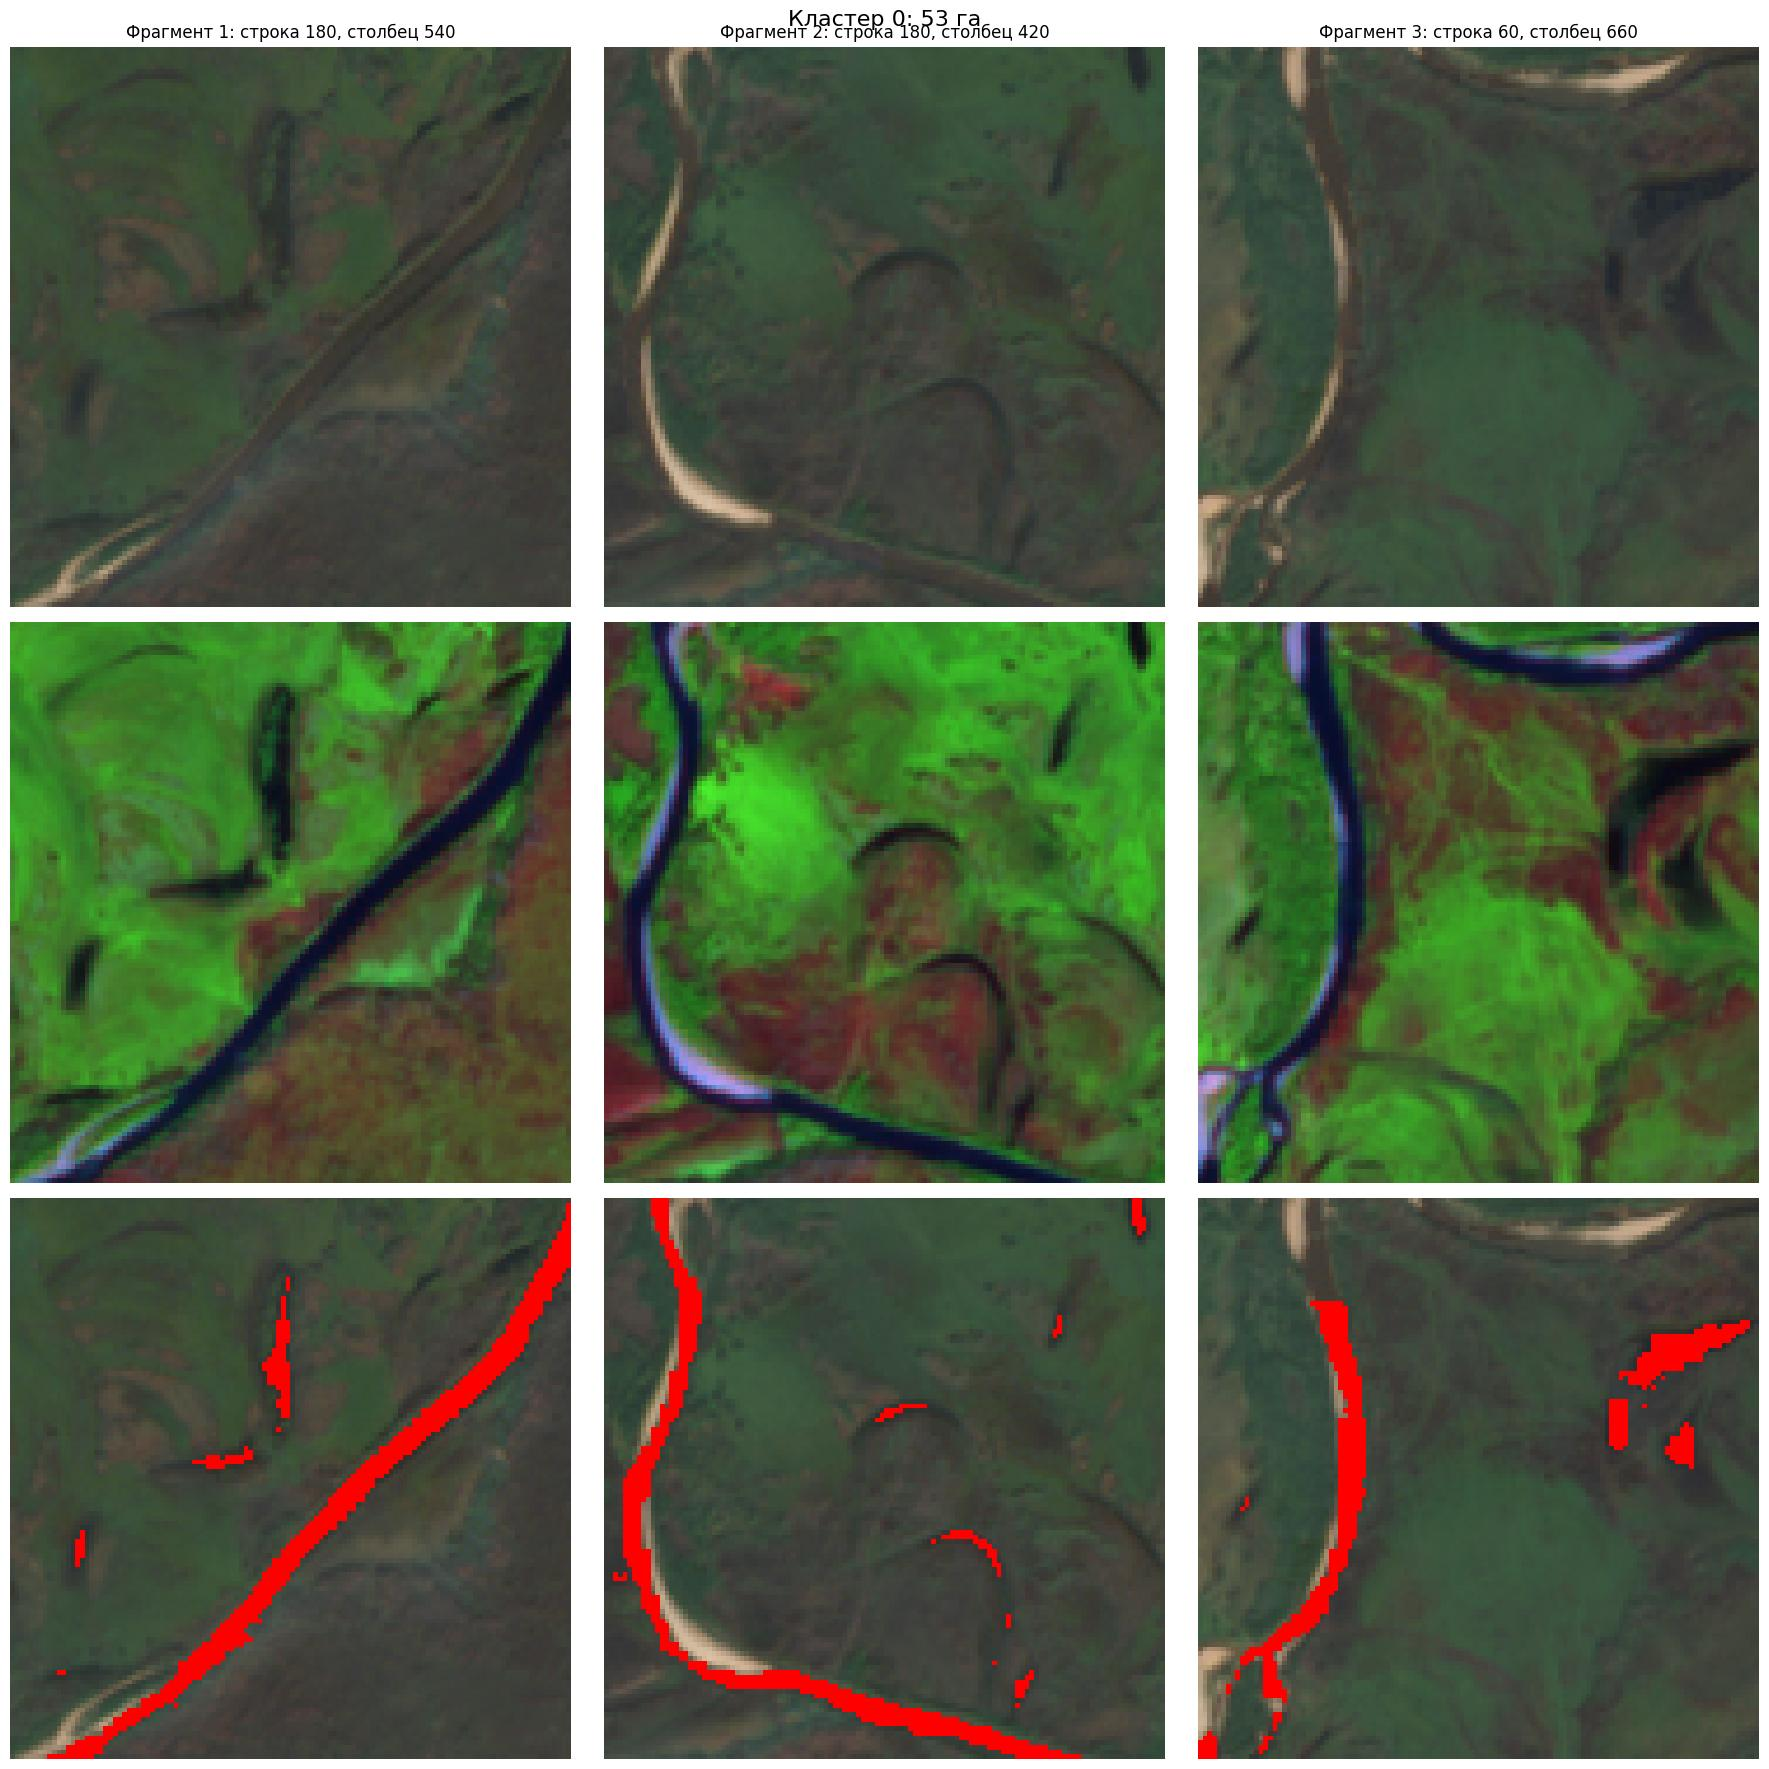

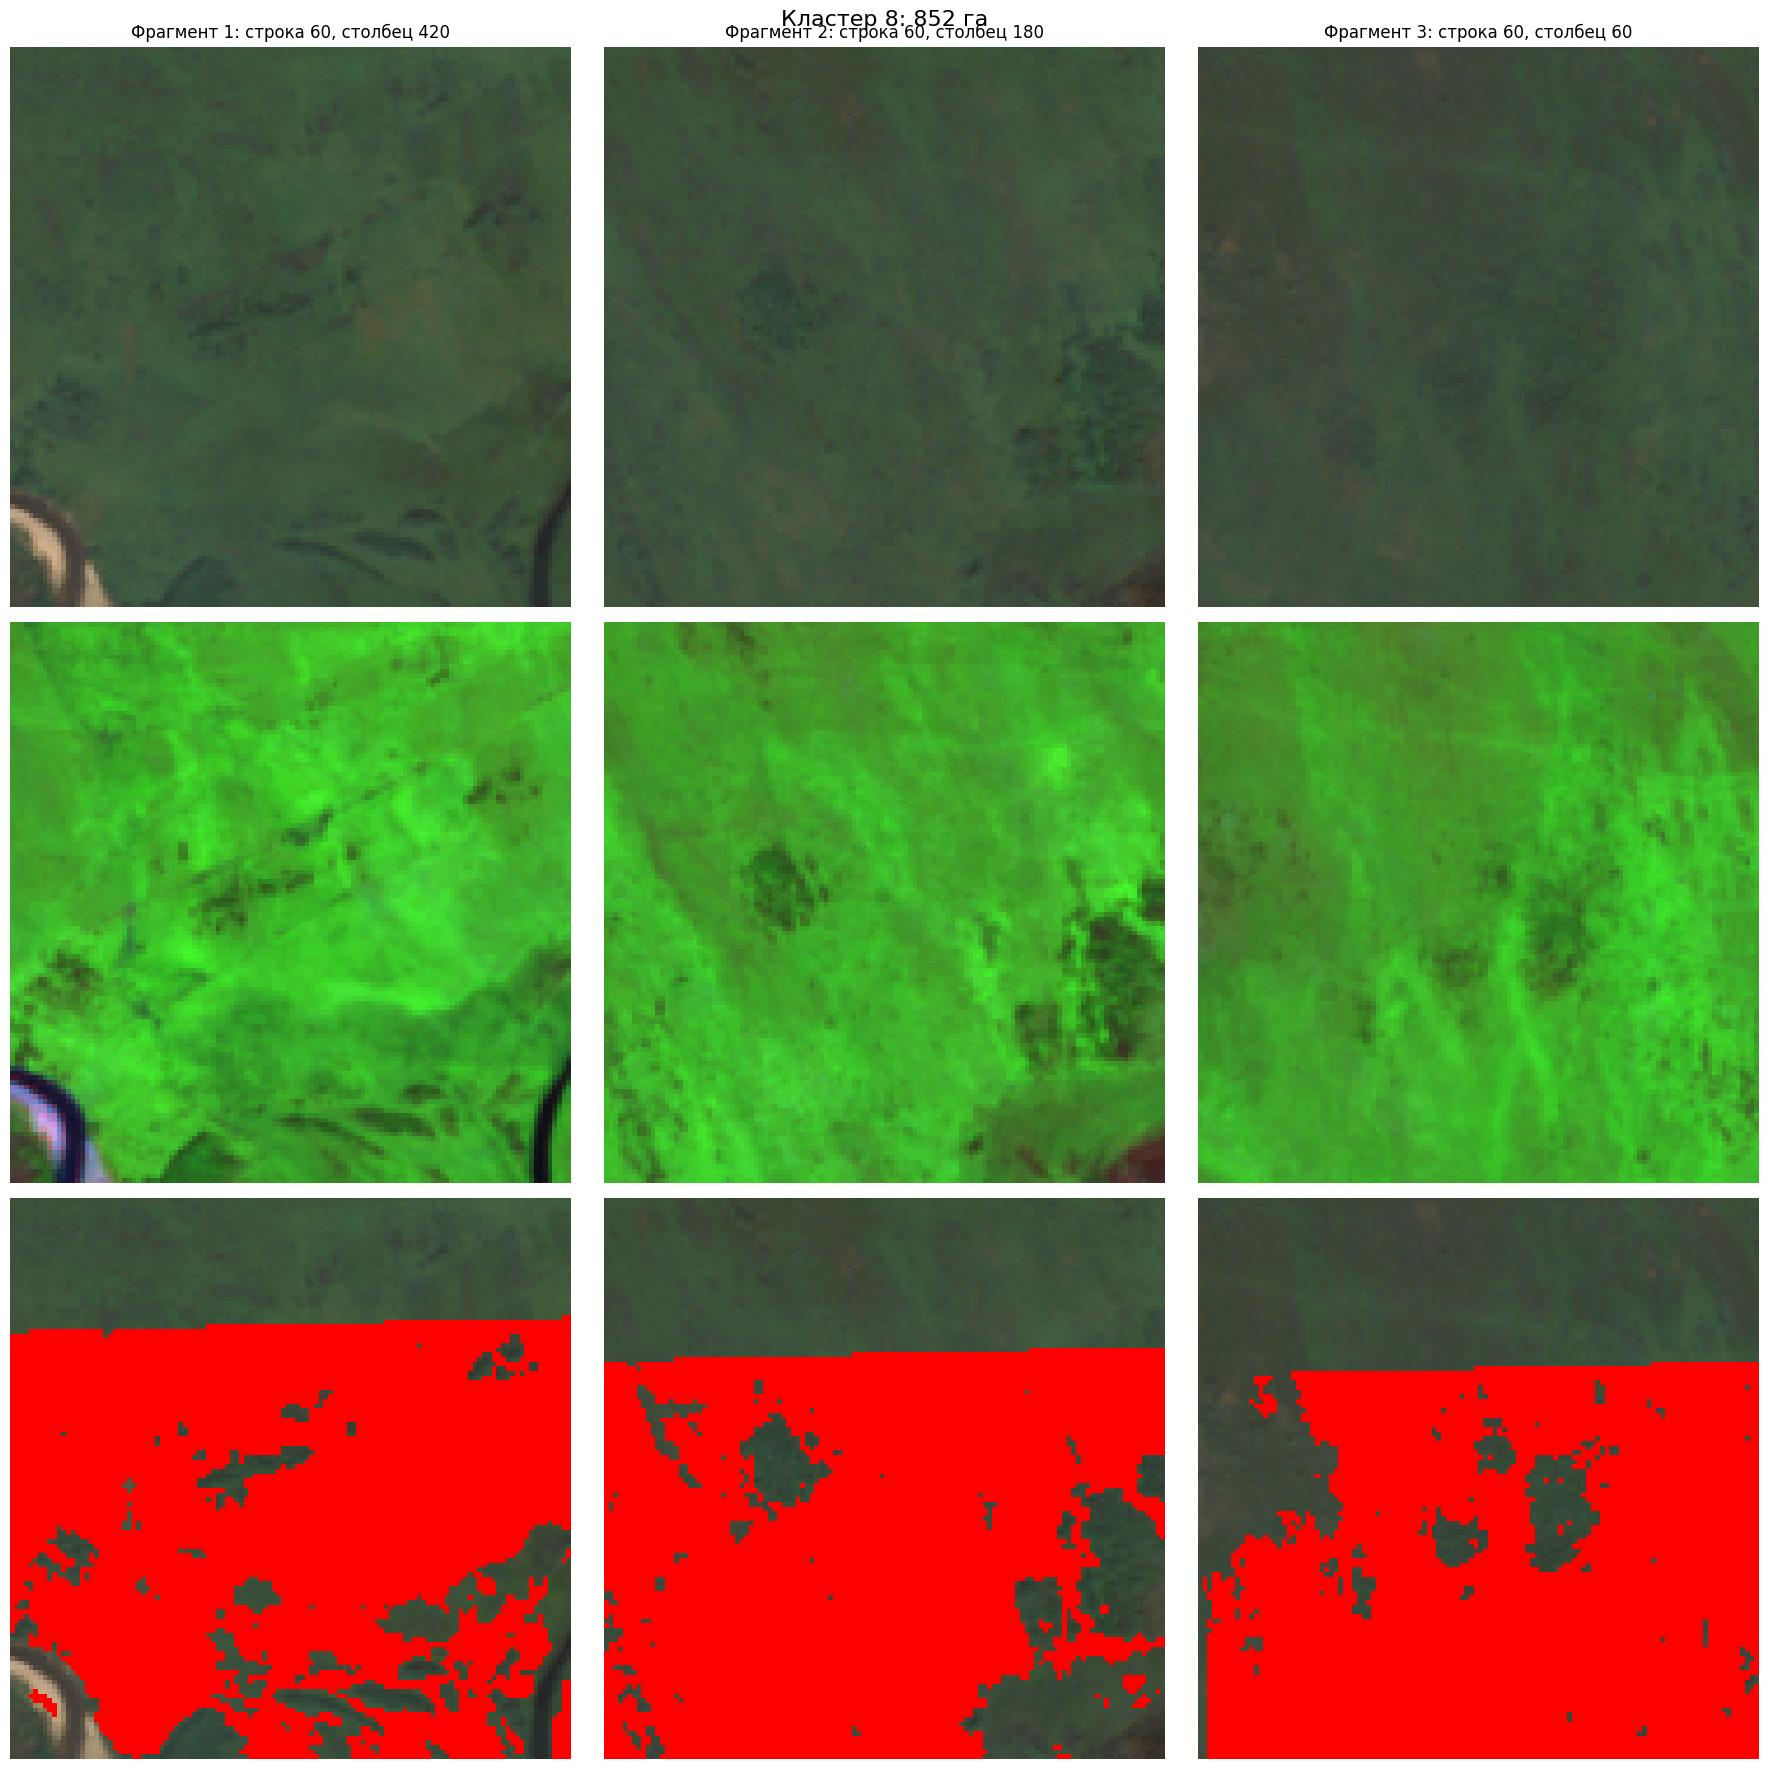

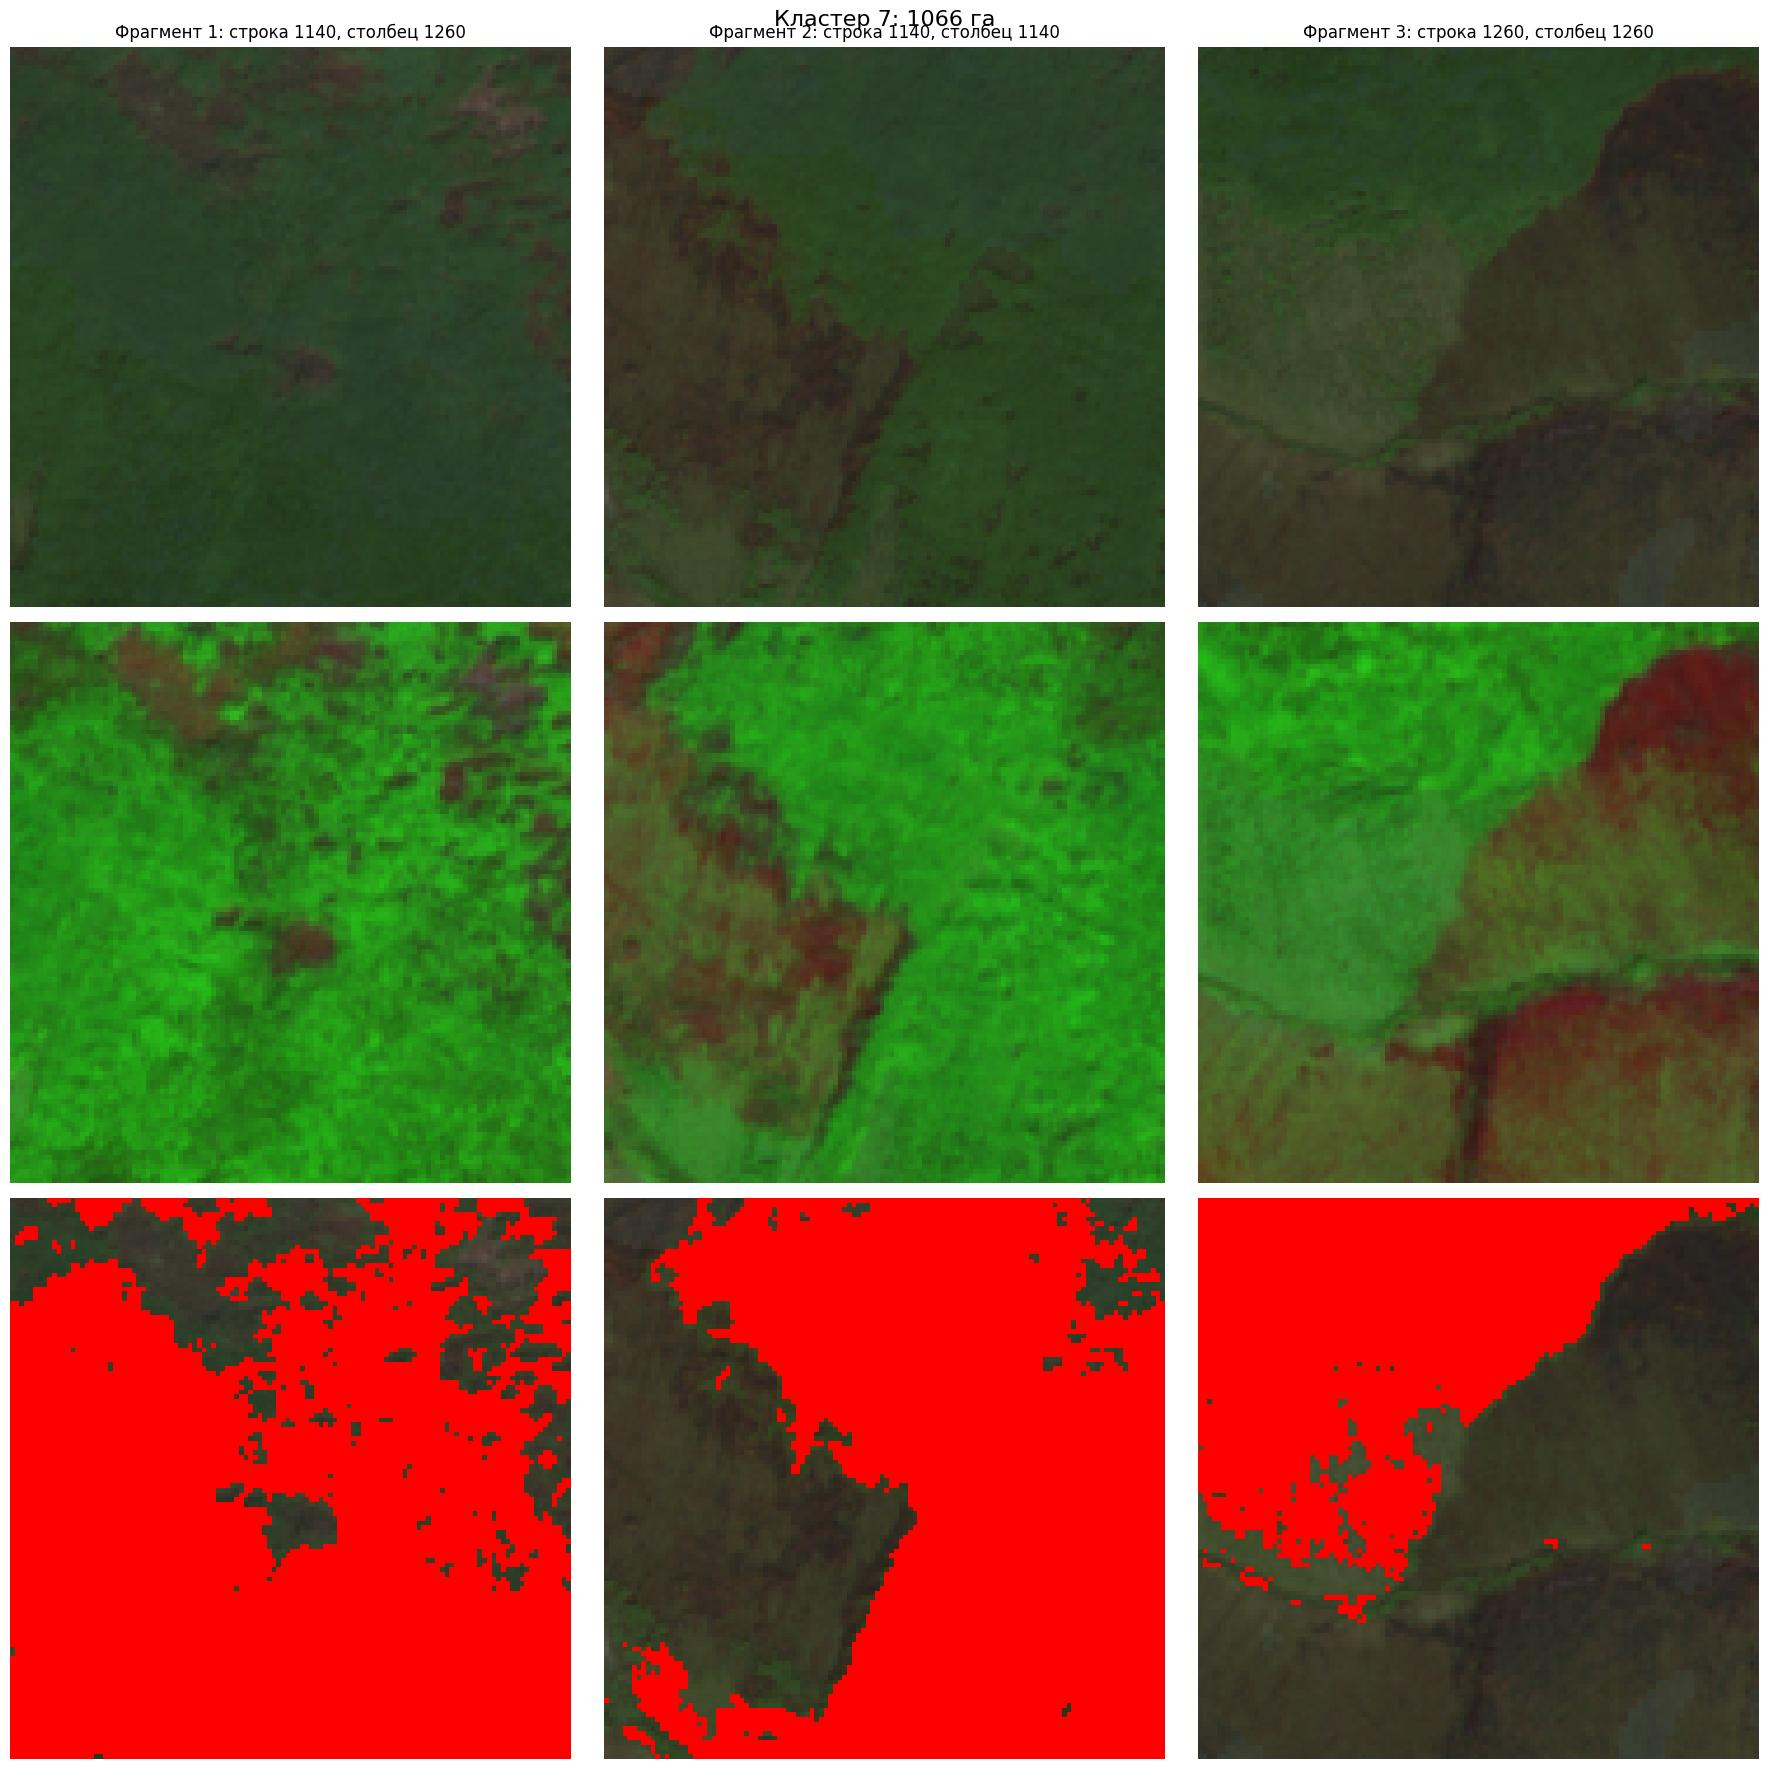

Иголки: [np.float64(0.0), np.float64(8.0), np.float64(7.0), np.float64(5.0), np.float64(4.0)]
Площадь иголок: 5431.5 га
Состав по Dynamic World: Деревья                   3234.8
Кустарники                1734.8
Трава                      372.9
Вода                        66.4
Культуры                    10.1
Затопл. растительность       7.3
Голая земля                  5.0
Снег и лед                   0.3
dtype: float64
Состав по классификации: Деревья                   2785.8
Кустарники                 963.8
Трава                      654.6
Затопл. растительность     643.5
Голая земля                280.8
Вода                        89.8
Культуры                    13.2
dtype: float64


In [29]:
profiles_sorted = profiles_df.sort_values('Необычность', ascending=False)
top3_unusual = profiles_sorted.head(3)['Кластер'].tolist()
print('Три самых необычных кластера:', top3_unusual)
for k in top3_unusual:
    row = profiles_df[profiles_df['Кластер'] == k].iloc[0]
    print(f'  Кластер {k}: площадь={row["Площадь, га"]:.1f} га, необычность={row["Необычность"]:.3f}')

for k in top3_unusual:
    mask_k = (labels == k) & valid
    zoom_views(mask_k, n=3, size=60, color=(1, 0, 0), title=f'Кластер {k}: {profiles_df[profiles_df["Кластер"]==k]["Площадь, га"].values[0]:.0f} га')

NEEDLES = [profiles_sorted.iloc[i]['Кластер'] for i in range(min(5, len(profiles_sorted)))]
print('Иголки:', NEEDLES)

needle_mask = np.isin(labels, NEEDLES) & valid
needle_area = needle_mask.sum() * PIXEL_AREA_HA
needle_dw = pd.Series(np.bincount(dw[needle_mask], minlength=9), index=DW_NAMES)
needle_cls = pd.Series(np.bincount(classification[needle_mask], minlength=9), index=DW_NAMES)
print(f'Площадь иголок: {needle_area:.1f} га')
print('Состав по Dynamic World:', (needle_dw[needle_dw > 0] * PIXEL_AREA_HA).sort_values(ascending=False).round(1))
print('Состав по классификации:', (needle_cls[needle_cls > 0] * PIXEL_AREA_HA).sort_values(ascending=False).round(1))

**Вопрос:** Что представляют собой выбранные кластеры? Опишите, как они выглядят на снимке в естественных цветах и в комбинации B12–B8–B4, их спектральный профиль, площадь и расположение. К каким классам их отнесли Dynamic World и ваша модель, и почему ни одна из карт не выделяет их отдельно?

**Ответ:**
пупупу Представляют объеденение тёмноховйной тайги(иголки). Выглядят как тёмно зелёненный пятна. Становится насчщенным ярко-зелённым и неоново-зелёным цветом. Подсветило воду красным цветом при спектральном профиле. Площадь 5431.5 га.

 Dynamic World: деревья 3234.8га, кустарники 1734га, трава 372.9.
 Моя карта: деревья 2785.8, затопленная растительность 643.5

 Не могут выделить поскольку нет как такового класса хвойный лес.

### **5.6. Как число кластеров меняет найденное**

**Задание 5.6.** Для каждого $K$ из `K_LIST` выведите три самых необычных кластера: необычность, площадь, доля площади, доля пикселей кластера, входящих в ваши «иголки» при $K = 12$ (`needle_mask`), и доля всех «иголок», попавших в этот кластер. Так видно, при каком $K$ интересующие вас объекты выделяются в отдельные кластеры и как они дробятся при большом $K$.

In [30]:
means_arr = np.array(means)[:, None, None]
stds_arr = np.array(stds)[:, None, None]

valid_flat = valid.ravel()
needle_mask_flat = needle_mask.ravel()

for K in K_LIST:
    idx = K_LIST.index(K)
    labels_K = cluster_maps[idx]
    labels_K_flat = labels_K.ravel()

    z_K = (bands[:len(LOCAL_BANDS)] - means_arr) / stds_arr
    z_K_flat = z_K.reshape(z_K.shape[0], -1).T

    centroids_K = np.zeros((K, z_K_flat.shape[1]))
    for k in range(K):
        mask_k = (labels_K_flat == k) & valid_flat
        if mask_k.sum() > 0:
            centroids_K[k] = z_K_flat[mask_k].mean(axis=0)

    unusualness_K = np.sqrt((centroids_K ** 2).sum(axis=1))
    top3_idx = np.argsort(-unusualness_K)[:3]

    print(f'\nK = {K}:')
    for ti in top3_idx:
        mask_ti = (labels_K_flat == ti) & valid_flat
        area_K = mask_ti.sum() * PIXEL_AREA_HA
        pct_K = mask_ti.sum() / valid_flat.sum() * 100

        needle_in_cluster = ((labels_K_flat == ti) & needle_mask_flat).sum()
        needle_total = needle_mask_flat.sum()
        needle_in_pct = needle_in_cluster / needle_total * 100 if needle_total > 0 else 0

        print(f'  Кластер {ti}: необычность={unusualness_K[ti]:.3f}, '
              f'площадь={area_K:.0f} га, доля={pct_K:.2f}%, '
              f'иголок={needle_in_pct:.1f}%')



K = 6:
  Кластер 4: необычность=3.940, площадь=1508 га, доля=7.70%, иголок=27.7%
  Кластер 2: необычность=3.415, площадь=1680 га, доля=8.57%, иголок=21.8%
  Кластер 0: необычность=2.671, площадь=3594 га, доля=18.34%, иголок=33.4%

K = 12:
  Кластер 0: необычность=9.529, площадь=53 га, доля=0.27%, иголок=1.0%
  Кластер 8: необычность=4.454, площадь=852 га, доля=4.35%, иголок=15.7%
  Кластер 7: необычность=3.944, площадь=1066 га, доля=5.44%, иголок=19.6%

K = 18:
  Кластер 15: необычность=20.991, площадь=12 га, доля=0.06%, иголок=0.1%
  Кластер 17: необычность=9.634, площадь=51 га, доля=0.26%, иголок=0.9%
  Кластер 12: необычность=4.840, площадь=458 га, доля=2.34%, иголок=8.4%


**Вопрос:** При каком наименьшем $K$ ваши объекты выделяются в собственный кластер? Что происходит с ними при $K = 6$ и при $K = 18$? Какое $K$ вы бы выбрали для поиска объектов этого типа на соседних территориях?

**Ответ:**

При 12К, идеальная середина.

При 6К, снимки получаются очень большими и получилось так, что процент количества иголок большой, связано это с тем, что в класс иголок попали кустарники, деревь, трава и тд.

При 18К, ситуация совсем наборот, снимки получаются маленькми и пк начинает мельчить и реагировать на любую тень или пятно. При этом показатель необычности самые большой , а доля иголок очень маленькая.

### **5.7. Необычные пиксели вне кластеров**

Отдельные необычные объекты не образуют своего кластера, но их пиксели находятся далеко от всех центроидов (см. лекция «Кластеризация спутниковых снимков в среде Google Earth Engine», **раздел 5.3**). Центроиды `centroids` уже рассчитаны в разделе 5.3.

**Задание 5.7.** Рассчитайте расстояние от каждого пикселя до ближайшего центроида и карту `distance_map`. Найдите 0,1% самых далёких пикселей среди пикселей, не входящих в `NEEDLES`, покажите их на снимке и крупным планом. Определите, что это за объекты.

In [31]:
# Совет: квадраты расстояний всех пикселей до всех центроидов без больших промежуточных массивов:
# (z ** 2).sum(axis=1)[:, None] - 2 * z @ centroids.T + (centroids ** 2).sum(axis=1)[None]
# Ваш код: расстояние до ближайшего центроида, distance_map, 0,1% самых далёких вне needle_mask, карта и zoom_views

Порог 0,1%: 6.106, пикселей: 1417


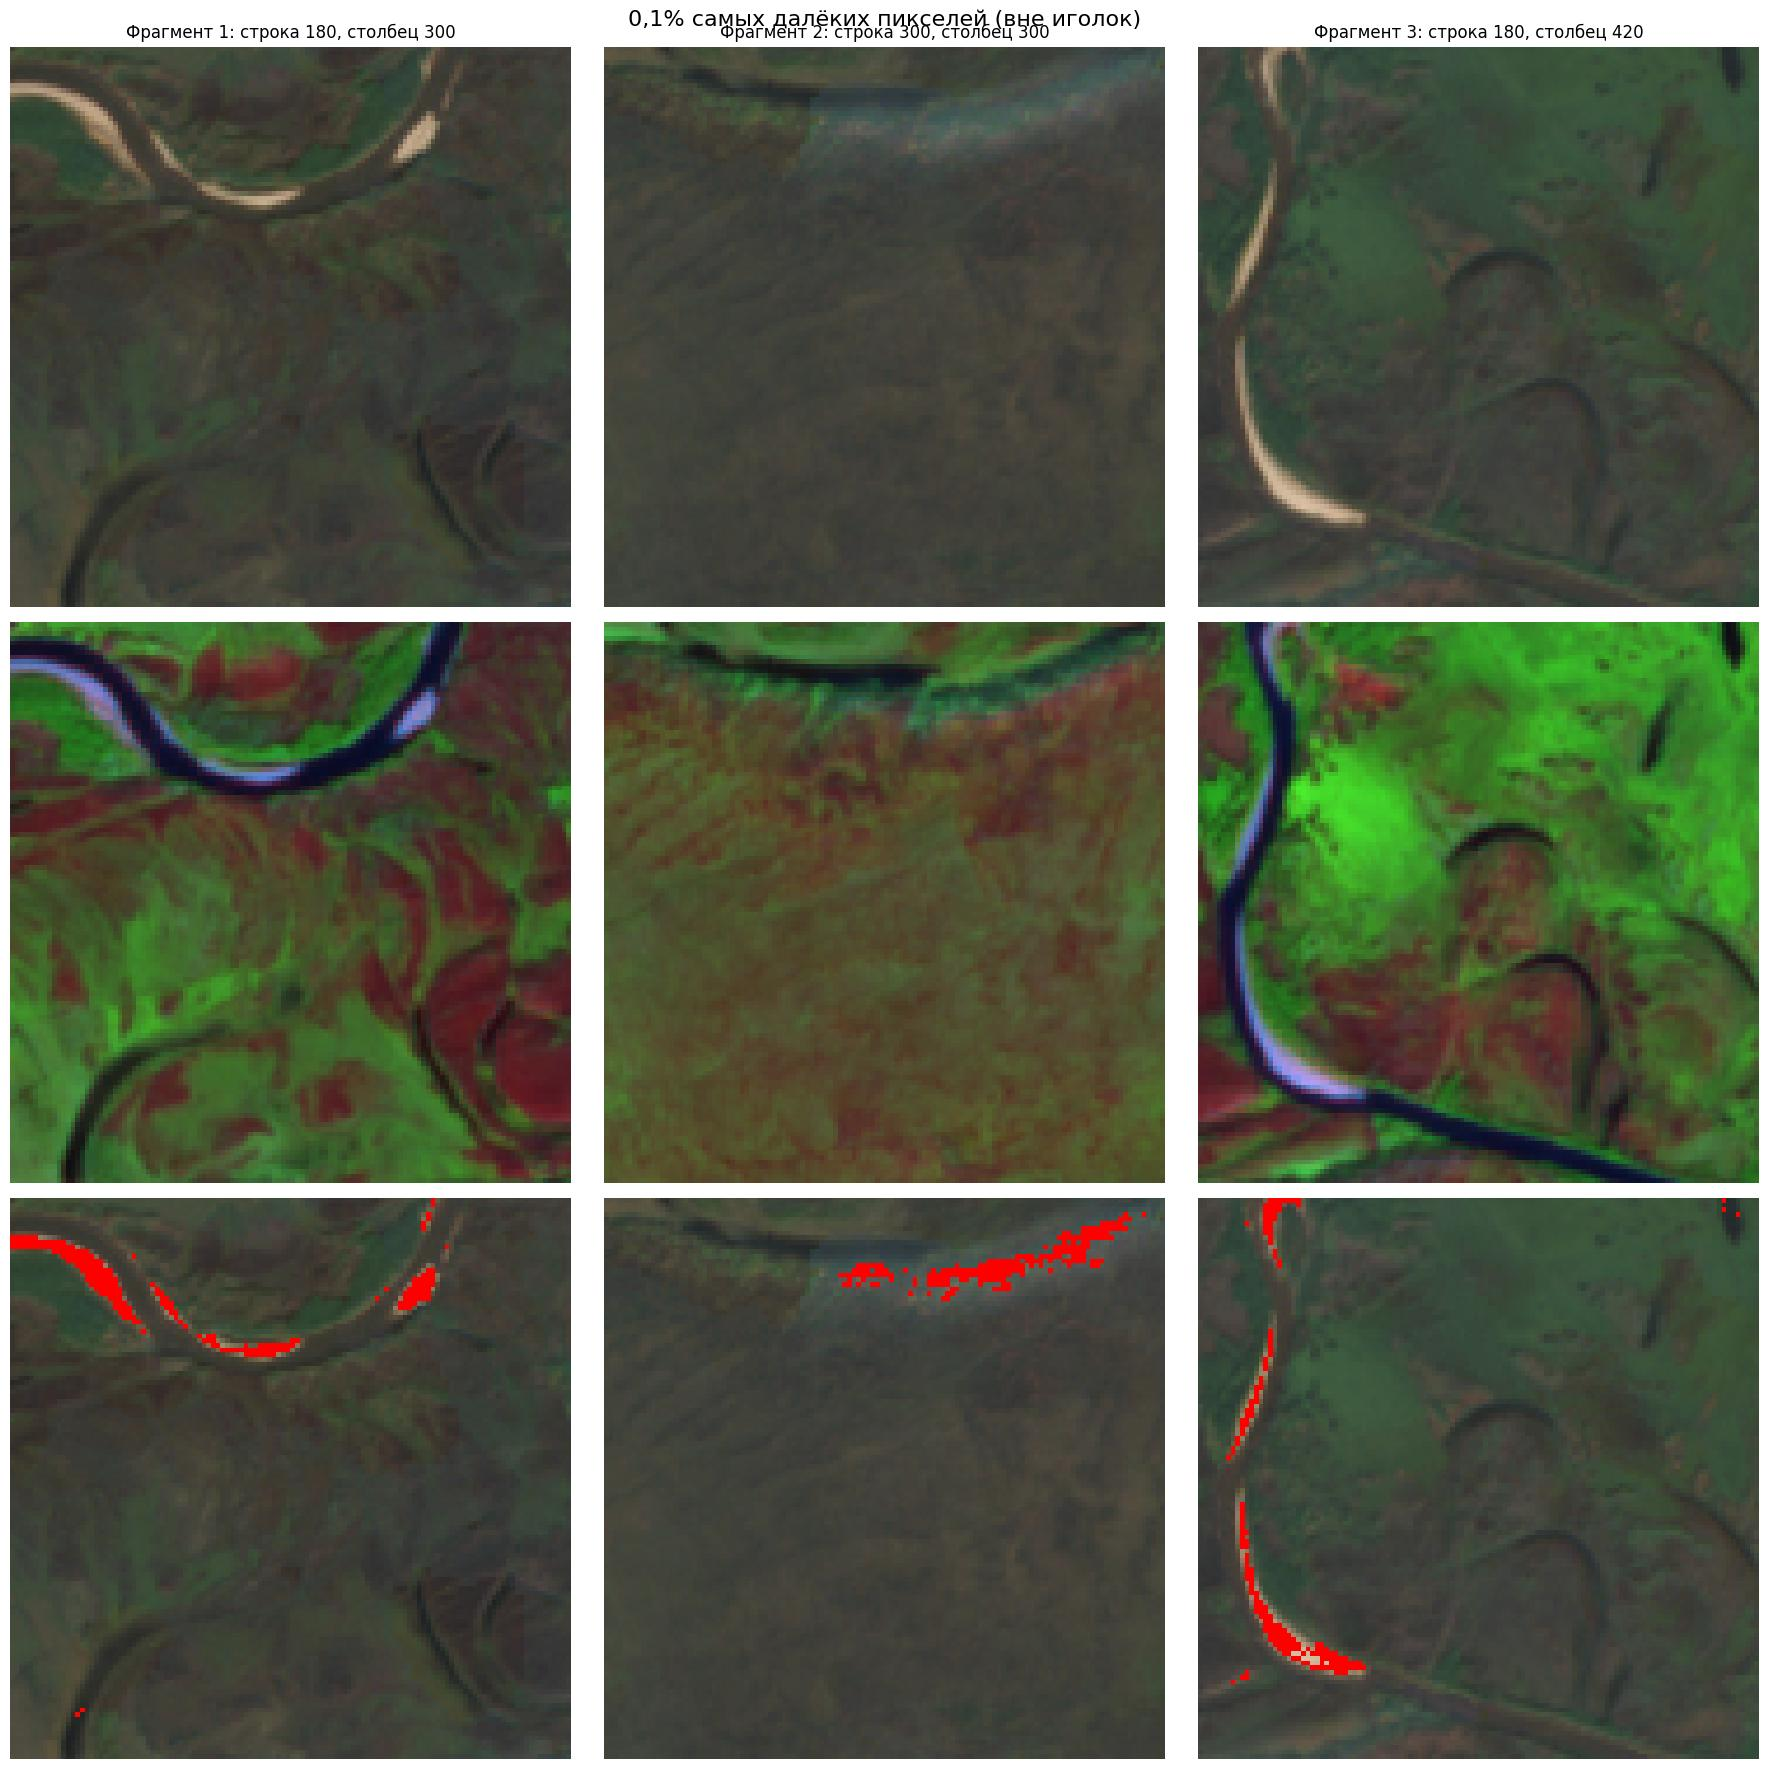

In [32]:
centroids_arr = centroids
means_arr = np.array(means)[:, None, None]
stds_arr = np.array(stds)[:, None, None]

z_all = (bands[:len(LOCAL_BANDS)] - means_arr) / stds_arr
z_all_flat = z_all.reshape(z_all.shape[0], -1).T

sq_dists = (z_all_flat ** 2).sum(axis=1)[:, None] - 2 * z_all_flat @ centroids_arr.T + (centroids_arr ** 2).sum(axis=1)[None]
sq_dists = np.maximum(sq_dists, 0)
dist_map_flat = np.sqrt(sq_dists.min(axis=1))
dist_map = dist_map_flat.reshape(H, W)

outside_needles = valid & (~needle_mask)
far_values = dist_map[outside_needles]
threshold_01 = np.percentile(far_values, 99.9)
rare_mask = (dist_map >= threshold_01) & outside_needles

print(f'Порог 0,1%: {threshold_01:.3f}, пикселей: {rare_mask.sum()}')
zoom_views(rare_mask, n=3, size=60, color=(1, 0, 0))


**Вопрос:** Что оказалось среди самых необычных пикселей? Это отдельные объекты, границы между разными поверхностями или артефакты композита (остатки облаков, теней)? Есть ли среди них объекты, которые вы пропустили бы при просмотре снимка?

**Ответ:**

На картинках 1 и 3 красными пятнами чётко выделена береговая линия реки, то есть переход от воды к пляжу(песочному).

На картинке 2 красным выделена отмель, может какой-то песок, необычный(кварцовый)

Остатки облаков, теней я не нашёл если честно

Да, есть. Это вот как раз песочек из 2 картинки.

### **5.8. Проверка гипотез и выводы по разделу 5**

**Задание 5.8.** Вернитесь к таблице 2. Для каждой гипотезы укажите, подтвердилась ли она, каким кластером или каким способом найден объект, его площадь и класс Dynamic World.

**Ответ:**

| № | Гипотеза | Статус | Кластером/способом | Площадь и класс Dynamic World |
|---|---|---|---|---|
| 1 | Вырубка леса | Подтвердилась | Выделена с помощью кластера 9 (вырубки/нарушенные участки). Отдельные зарастающие участки также ушли в «травяной» кластер 8. | Площадь Кластера 9 — 2192.98 га.<br><br>Dynamic World относит эти зоны преимущественно к классам Деревья (49%) и Кустарники (44%). |
| 2 | Мини-гора, Вечная мерзлота | Подтвердилась частично | Каменная россыпь на вершине. Успешно выделена с помощью кластера 11. | Площадь Кластера 11 — 1675.68 га.<br><br>Dynamic World относит этот тип местности к Кустарникам (64%) и Деревьям (29%) из-за разреженного стланика на склонах. |
| 3 | Горная река или mini-болото | Подтвердилась полностью | Открытая вода — кластер 0. | Открытая вода — 53.08 га. Заболоченные долины (Кластер 5) — 1758.81 га.<br><br>Dynamic World определяет русла как Вода (97%), а поймы — как Кустарники (85%). |


Опишите, что нашла кластеризация из того, чего нет в легенде Dynamic World и что не выделил ваш классификатор; какие объекты плохо видны в естественных цветах, но выделяются по инфракрасным каналам; как выбор $K$ влияет на результат.

**Вывод:**

Кластеризация нашла обгоревшую землю, вырубку леса и каменные вершины гор.

Плохо видны вода тобишь влажность какая-то.



---

## **6. Сжатие изображений кластеризацией цветов (для бакалавров)**

Кластеризация цветов заменяет все цвета изображения палитрой из $K$ цветов — центроидов кластеров (см. лекция «Кластеризация спутниковых снимков в среде Google Earth Engine», **раздел 6**). Выигрыш в размере получается, только если результат сохранён как **палитра + номера цветов пикселей**. В этом разделе вы проверите, для каких изображений и при каком числе цветов такое сжатие действительно выгодно по сравнению с обычными форматами.

### **6.1. Изображения для экспериментов**

**Задание 6.1.** Загрузите в папку `photos` (панель «Файлы» слева, папка создаётся следующей ячейкой) **две свои фотографии** в формате JPEG:
- фотографию с плавными переходами цвета — небо, портрет, пейзаж, животное на однородном фоне;
- фотографию с множеством мелких деталей и ярких цветов — рынок, цветник, городская улица.

Пропишите имена файлов в словаре `PHOTOS`. Кроме фотографий в эксперименты войдут два изображения вашей территории: фрагмент карты кластеров $K = 12$ из раздела 5 (тематическая карта с небольшим числом цветов) и тот же фрагмент снимка в естественных цветах. Все изображения уменьшаются так, чтобы большая сторона была не больше 1024 пикселей, — это ускоряет расчёты и делает изображения сопоставимыми.

In [33]:
os.makedirs('photos', exist_ok=True)

In [34]:
PHOTOS = {
    'Фото с плавными переходами': 'photos/work_5_1.1.jpg',   # имя вашего файла
    'Фото с мелкими деталями': 'photos/work_5_1.2.jpg',
}

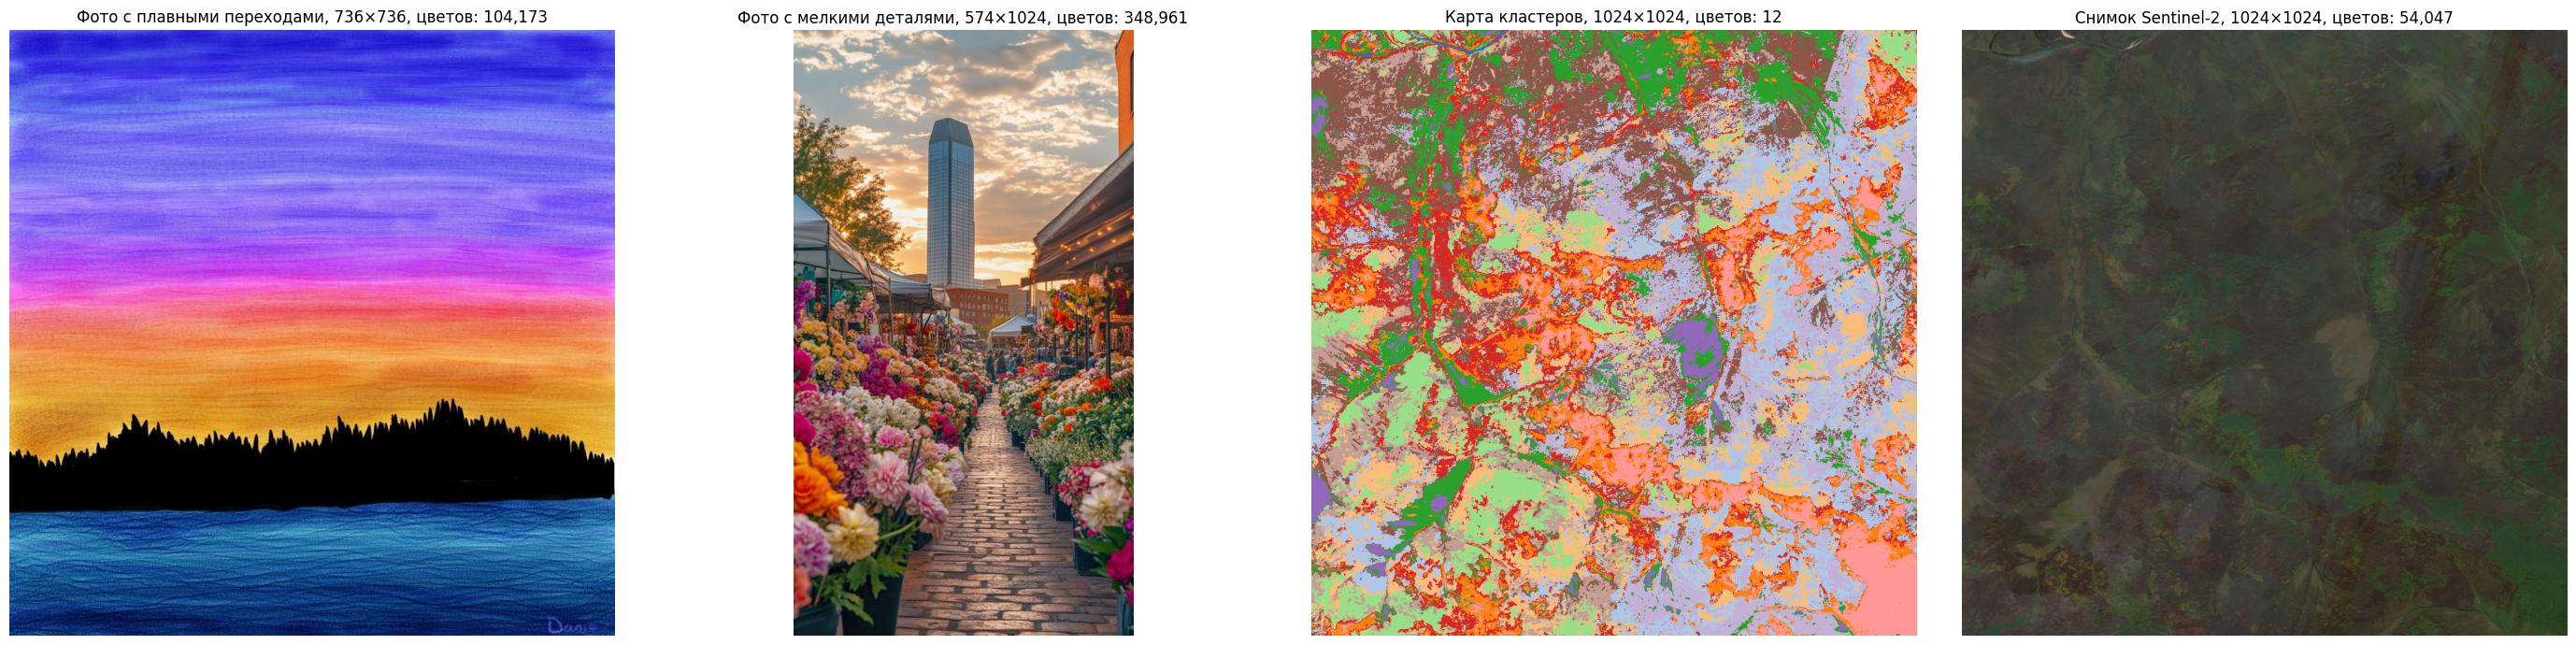

In [36]:
#@title Готовая функция: подготовка изображений
MAX_SIDE = 1024

def load_photo(path, max_side=MAX_SIDE):
    """RGB-массив фотографии, уменьшенной до max_side пикселей по большей стороне."""
    img = Image.open(path).convert('RGB')
    img.thumbnail((max_side, max_side))
    return np.array(img)

images = {name: load_photo(path) for name, path in PHOTOS.items()}

# Фрагмент территории: центральный квадрат растра не больше MAX_SIDE пикселей
side = min(H, W, MAX_SIDE)
r0, c0 = (H - side) // 2, (W - side) // 2
window = np.s_[r0:r0 + side, c0:c0 + side]
cluster_rgb = np.round(cluster_colors[:, :3] * 255).astype('uint8')   # цвета кластеров в RGB
images['Карта кластеров'] = cluster_rgb[np.clip(labels[window], 0, K - 1)]
images['Снимок Sentinel-2'] = (rgb[window] * 255).astype('uint8')

fig, axes = plt.subplots(1, len(images), figsize=(7 * len(images), 7))
for ax, (name, img) in zip(axes, images.items()):
    ax.imshow(img)
    ax.set_title(f'{name}, {img.shape[1]}×{img.shape[0]}, цветов: {len(np.unique(img.reshape(-1, 3), axis=0)):,}')
    ax.axis('off')
plt.tight_layout()
plt.show()

### **6.2. Как сохранять результат**

Размер файла — главный показатель эффективности сжатия, поэтому сохраняйте изображения **строго одним из способов из таблицы 4** и измеряйте размер **настоящего файла на диске** функцией `os.path.getsize`. Все файлы раздела сохраняйте в папку `compressed/<название изображения>/`.

#### **Таблица 4. Способы сохранения**

| **Способ** | **Код** | **Что записывается в файл** |
|---|---|---|
| PNG без потерь — эталон размера | `Image.fromarray(img).save(path, format='PNG', optimize=True)` | 3 байта цвета на пиксель, сжатие без потерь |
| JPEG, качество 90 — обычное сжатие фотографий | `Image.fromarray(img).save(path, format='JPEG', quality=90)` | Сжатие с потерями, рассчитанное на фотографии |
| **Палитровый PNG — результат кластеризации** | `p_img = Image.frombytes('P', (w, h), indices.astype('uint8').tobytes())`<br>`p_img.putpalette(palette.flatten().tolist())`<br>`p_img.save(path, format='PNG', optimize=True)` | Палитра из $K$ цветов и номер цвета для каждого пикселя: 1 бит на пиксель при 2 цветах, 4 бита при 16, 8 бит при 256 |

Обратите внимание:
- номера цветов `indices` должны иметь тип `uint8` (от 0 до 255), поэтому $K \le 256$;
- параметр `mode` функции `Image.fromarray` в новых версиях Pillow устарел, поэтому палитровое изображение создаётся через `Image.frombytes`;
- изображение `palette[indices]` (восстановленные цвета) нужно только для просмотра и расчёта качества — если сохранить его как RGB-PNG или JPEG, выигрыша от кластеризации не будет (это вы проверите в разделе 6.4).

**Задание 6.2.** Допишите две функции:
- `quantize_kmeans(image, k, sample_size=50000, seed=42)` — обучает `KMeans(n_clusters=k, n_init=1, random_state=seed)` на случайной подвыборке `sample_size` пикселей (все пиксели, если `sample_size=None` или пикселей меньше), относит все пиксели к ближайшим центроидам и возвращает палитру `palette` (`uint8`, форма $(k, 3)$), индексы `indices` (`uint8`, форма $(h, w)$) и время работы в секундах;
- `save_palette_png(palette, indices, path)` — сохраняет палитровый PNG по таблице 4 и возвращает размер файла в КБ.

In [37]:
def quantize_kmeans(image, k, sample_size=50000, seed=42):
    """Квантизация RGB-изображения до k цветов методом K-средних: палитра, индексы и время, с."""
    start = time.perf_counter()
    h_img, w_img, _ = image.shape
    colors = image.reshape(-1, 3).astype('float32')
    n_pixels = colors.shape[0]
    if sample_size is None or sample_size >= n_pixels:
        sample = colors
    else:
        sample = colors[np.random.RandomState(seed).choice(n_pixels, sample_size, replace=False)]
    kmeans = KMeans(n_clusters=k, n_init=1, random_state=seed).fit(sample)
    palette = np.round(kmeans.cluster_centers_).astype('uint8')
    indices = kmeans.predict(colors).reshape(h_img, w_img).astype('uint8')
    return palette, indices, time.perf_counter() - start

def save_palette_png(palette, indices, path):
    """Палитровый PNG: таблица цветов и номер цвета каждого пикселя. Возвращает размер файла, КБ."""
    h, w = indices.shape
    p_img = Image.frombytes('P', (w, h), indices.astype('uint8').tobytes())
    p_img.putpalette(palette.flatten().tolist())
    p_img.save(path, format='PNG', optimize=True)
    return os.path.getsize(path) / 1024

In [38]:
#@title Готовые функции: сохранение без кластеризации и метрики качества
def save_rgb(img, path, **save_args):
    """Сохраняет RGB-массив в файл и возвращает размер, КБ."""
    Image.fromarray(img).save(path, **save_args)
    return os.path.getsize(path) / 1024

def quality(original, restored):
    """PSNR (дБ) и SSIM восстановленного изображения относительно исходного."""
    return (peak_signal_noise_ratio(original, restored, data_range=255),
            structural_similarity(original, restored, channel_axis=2, data_range=255))

for name in images:
    os.makedirs(f'compressed/{name}', exist_ok=True)

### **6.3. Размер, качество и время при разном числе цветов**

**Задание 6.3.** Для каждого изображения из `images`:
1. Сохраните эталоны без кластеризации: `compressed/<имя>/original.png` (PNG без потерь) и `compressed/<имя>/original_q90.jpg` (JPEG, качество 90). Для JPEG рассчитайте PSNR и SSIM относительно исходного изображения.
2. Для каждого `k` из `K_COLORS` выполните `quantize_kmeans`, сохраните палитровый PNG `compressed/<имя>/kmeans_<k>.png`, рассчитайте PSNR и SSIM восстановленного изображения `palette[indices]`.

Соберите две таблицы: `baselines` (столбцы `Изображение`, `PNG без потерь, КБ`, `JPEG 90, КБ`, `JPEG 90 PSNR`, `JPEG 90 SSIM`) и `results` (столбцы `Изображение`, `Цветов`, `Время, с`, `Палитровый PNG, КБ`, `PSNR`, `SSIM`). Сохраните палитры и индексы в словарь `quantized[(имя, k)]` — они понадобятся дальше. Если восстановленное изображение точно совпадает с исходным (так бывает, когда цветов в изображении не больше $K$), PSNR равен бесконечности.

In [39]:
K_COLORS = [2, 4, 8, 16, 32, 64, 128, 256]

In [40]:
K_COLORS = [2, 4, 8, 16, 32, 64, 128, 256]
baselines = {}
results_list = []
quantized = {}

for name, img in images.items():
    os.makedirs(f'compressed/{name}', exist_ok=True)

    png_size = save_rgb(img, f'compressed/{name}/original.png', format='PNG', optimize=True)
    baselines[name] = {'PNG без потерь, КБ': png_size}

    jpg_path = f'compressed/{name}/original_q90.jpg'
    jpg_size = save_rgb(img, jpg_path, format='JPEG', quality=90)
    jpg_psnr, jpg_ssim = quality(img, np.array(Image.open(jpg_path)))
    baselines[name].update({'JPEG 90, КБ': jpg_size, 'JPEG 90 PSNR': jpg_psnr, 'JPEG 90 SSIM': jpg_ssim})

    for k in K_COLORS:
        palette, indices, elapsed = quantize_kmeans(img, k)
        png_k_size = save_palette_png(palette, indices, f'compressed/{name}/kmeans_{k}.png')
        restored = palette[indices]
        psnr, ssim = quality(img, restored)
        results_list.append({
            'Изображение': name, 'Цветов': k, 'Время, с': elapsed,
            'Палитровый PNG, КБ': png_k_size, 'PSNR': psnr, 'SSIM': ssim
        })
        quantized[(name, k)] = (palette, indices)

results = pd.DataFrame(results_list)
baselines = pd.DataFrame.from_dict(baselines, orient='index')

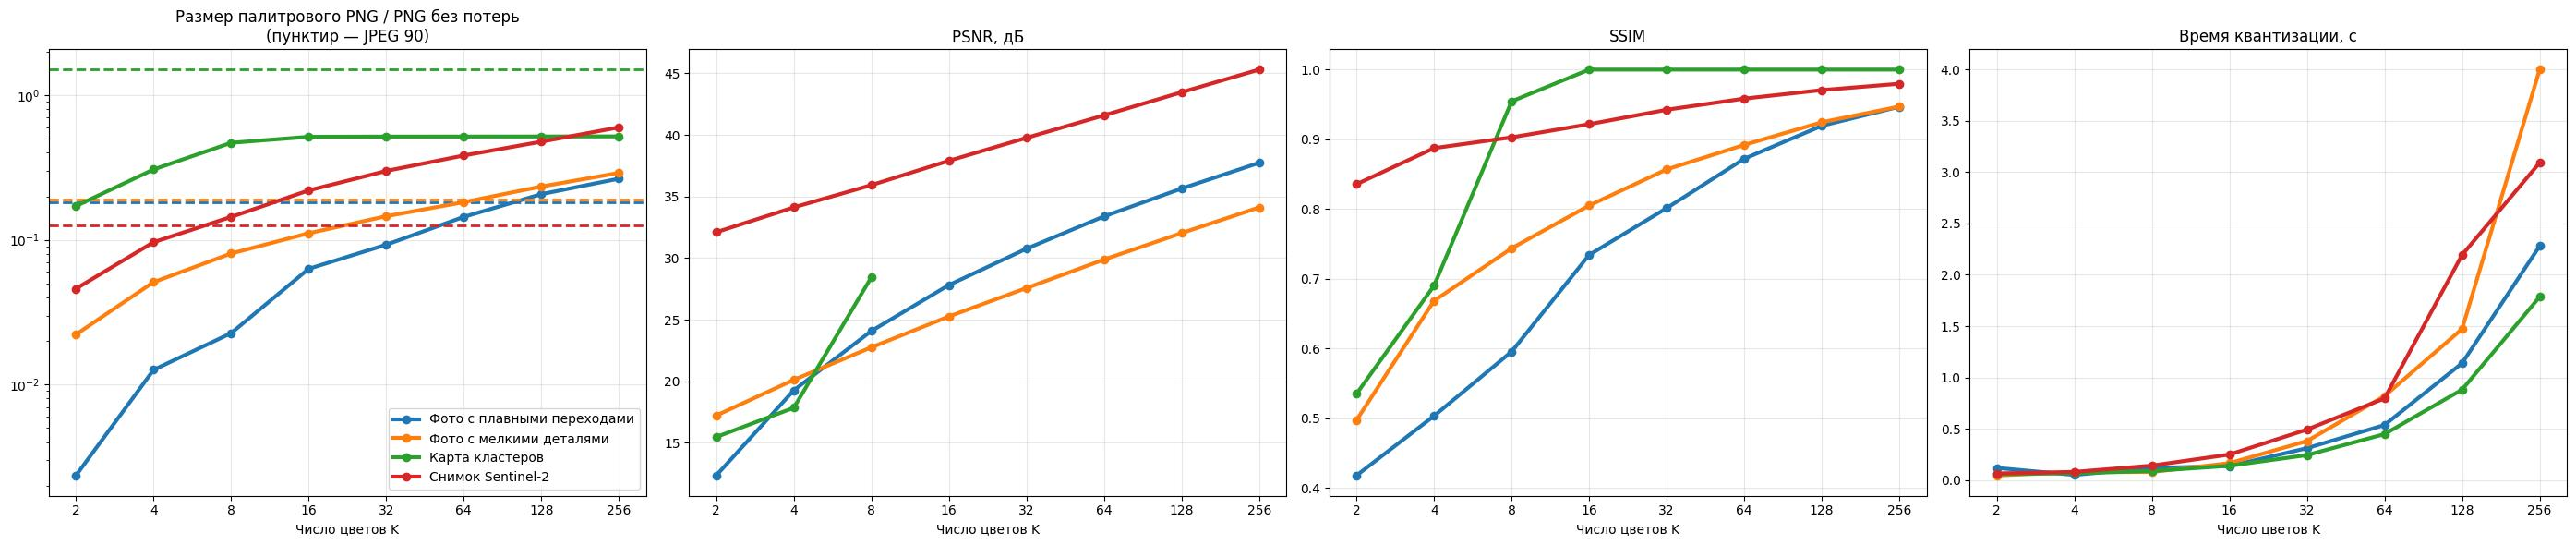

Изображение,Карта кластеров,Снимок Sentinel-2,Фото с мелкими деталями,Фото с плавными переходами
Цветов,,,,
2,0.06,0.07,0.05,0.12
4,0.07,0.08,0.08,0.05
8,0.09,0.14,0.08,0.12
16,0.14,0.25,0.17,0.14
32,0.25,0.49,0.38,0.31
64,0.45,0.80,0.82,0.54
128,0.88,2.19,1.47,1.14
256,1.79,3.09,4.00,2.28


Изображение,Карта кластеров,Снимок Sentinel-2,Фото с мелкими деталями,Фото с плавными переходами
Цветов,,,,
2,70.8,62.6,22.4,1.6
4,126.7,131.1,51.6,8.4
8,193.7,196.1,81.3,15.0
16,213.2,298.9,112.3,41.8
32,213.8,407.3,147.3,61.3
64,213.9,521.0,184.1,95.5
128,214.1,649.0,236.2,137.2
256,214.5,814.8,293.3,175.5


In [41]:
#@title Готовый код: графики размера, качества и времени
fig, axes = plt.subplots(1, 4, figsize=(28, 6))
for name, part in results.groupby('Изображение', sort=False):
    ratio = part['Палитровый PNG, КБ'] / baselines.loc[name, 'PNG без потерь, КБ']
    line, = axes[0].plot(part['Цветов'], ratio, 'o-', linewidth=3, label=name)
    axes[0].axhline(baselines.loc[name, 'JPEG 90, КБ'] / baselines.loc[name, 'PNG без потерь, КБ'],
                    color=line.get_color(), linestyle='--', linewidth=2)
    axes[1].plot(part['Цветов'], part['PSNR'], 'o-', linewidth=3, color=line.get_color())
    axes[2].plot(part['Цветов'], part['SSIM'], 'o-', linewidth=3, color=line.get_color())
    axes[3].plot(part['Цветов'], part['Время, с'], 'o-', linewidth=3, color=line.get_color())
titles = ['Размер палитрового PNG / PNG без потерь\n(пунктир — JPEG 90)', 'PSNR, дБ', 'SSIM', 'Время квантизации, с']
for ax, title in zip(axes, titles):
    ax.set_xscale('log', base=2)
    ax.set_xticks(K_COLORS, K_COLORS)
    ax.set_xlabel('Число цветов K')
    ax.set_title(title)
    ax.grid(alpha=0.3)
axes[0].set_yscale('log')
axes[0].legend()
plt.tight_layout()
plt.show()
display(results.pivot(index='Цветов', columns='Изображение', values='Время, с').round(2))
results.pivot(index='Цветов', columns='Изображение', values='Палитровый PNG, КБ').round(1)

**Вопрос:** Во сколько раз палитровый PNG при 16 цветах меньше PNG без потерь для каждого изображения? Для какого изображения выигрыш наибольший и почему? Как растёт время квантизации с ростом $K$?

**Ответ:**

нуууууууууууу

Фото заката где-то плюс минус в 20 раз уменьштлось

Фото улицы с цветами, где-то в 10 раз

Тайга в 11 раза

Для изображения с закатом более выиграшное

Растёт ВЗРЫВНЫМ образом, то резко.

### **6.4. Что будет, если сохранить результат неправильно**

**Задание 6.4.** Для каждого изображения при $K = 16$ сохраните восстановленное изображение `palette[indices]` как RGB-PNG (`kmeans_16_rgb.png`) и как JPEG качества 90 (`kmeans_16_q90.jpg`). Сравните размеры с палитровым PNG `kmeans_16.png` и с эталонами в таблице `wrong`.

In [42]:
wrong = {}
for name in images:
    palette, indices = quantized[(name, 16)]
    restored = palette[indices]

    rgb_png_size = save_rgb(restored, f'compressed/{name}/kmeans_16_rgb.png', format='PNG', optimize=True)
    rgb_jpg_size = save_rgb(restored, f'compressed/{name}/kmeans_16_q90.jpg', format='JPEG', quality=90)
    pal_png_size = save_palette_png(*quantized[(name, 16)], f'compressed/{name}/kmeans_16.png')

    wrong[name] = {
        'Палитровый PNG': pal_png_size,
        'RGB-PNG': rgb_png_size,
        'JPEG 90': rgb_jpg_size
    }

wrong_df = pd.DataFrame(wrong).T
print(wrong_df)

                            Палитровый PNG     RGB-PNG     JPEG 90
Фото с плавными переходами       41.808594   61.808594  121.591797
Фото с мелкими деталями         112.303711  246.787109  230.669922
Карта кластеров                 213.150391  413.360352  621.087891
Снимок Sentinel-2               298.932617  817.855469  176.098633


**Вопрос:** Во сколько раз RGB-PNG и JPEG квантизованного изображения тяжелее палитрового PNG? Почему JPEG квантизованного изображения может оказаться не меньше JPEG исходного?

**Ответ:**

Закат:

RGB-PNG тяжелее в 1.5 раза

JPEG тяжелее в 2.9 раза

Цвет:

RGB-PNG тяжелее в 2.2 раза

JPEG тяжелее в 2.1 раза

Карта кластеров:

RGB-PNG тяжелее в 1.9 раза

JPEG тяжелее в 2.9 раза

Тайга:

RGB-PNG тяжелее в 2.7 раза

JPEG здесь оказался легче палитрового PNG в 1.7 раза





### **6.5. Подвыборка пикселей и время**

K-средних можно обучать не на всех пикселях, а на случайной подвыборке: центроиды получаются почти такими же, а время сокращается. Проверим, где граница.

**Задание 6.5.** Для первой фотографии и $K = 64$ выполните `quantize_kmeans` с `sample_size` из списка `[1000, 10000, 50000, None]` (`None` — все пиксели). Постройте таблицу `sampling`: размер подвыборки, время, PSNR, SSIM.

In [43]:
first_photo_name = list(images.keys())[0]
first_photo = images[first_photo_name]
K_test = 64
sampling_results = []
for sample_size in [1000, 10000, 50000, None]:
    palette, indices, elapsed = quantize_kmeans(first_photo, K_test, sample_size=sample_size)
    restored = palette[indices]
    psnr, ssim = quality(first_photo, restored)
    sampling_results.append({
        'Подвыборка': sample_size if sample_size else 'все',
        'Время, с': elapsed, 'PSNR': psnr, 'SSIM': ssim
    })
sampling_df = pd.DataFrame(sampling_results)
print(sampling_df)

  Подвыборка  Время, с       PSNR      SSIM
0       1000  0.101851  32.507421  0.866319
1      10000  0.196103  33.332972  0.869724
2      50000  0.525429  33.389718  0.872142
3        все  9.888433  33.432667  0.874047


**Вопрос:** Во сколько раз обучение на всех пикселях дольше, чем на 50 000? Насколько при этом меняется PSNR? Какой размер подвыборки вы бы рекомендовали и почему?

**Ответ:**

Примерно 18.82 раза.

На 0.042949

Выбрал бы 50 000, времени затрачиваем мало, качество SSIM ближе всего приближается к идеальному. При это PSNR в сравнении с 1000 вырос примерно на 0.8, а разница между 50 000 и всеми состваляет примерно 0.04

### **6.6. K-средних против встроенной квантизации PIL**

В библиотеке PIL есть собственная быстрая квантизация методом **медианного сечения** (`Image.quantize`): цветовое пространство рекурсивно делится пополам по самой «длинной» оси, пока не получится $K$ ячеек. В отличие от K-средних, метод не итеративный и не минимизирует ошибку восстановления цветов явно.

**Задание 6.6.** Для всех изображений и $K \in \{4, 16, 64\}$ получите палитровое изображение `Image.fromarray(img).quantize(colors=k, method=Image.Quantize.MEDIANCUT, dither=Image.Dither.NONE)`, измерьте время, сохраните его как `mediancut_<k>.png` (`optimize=True`), восстановите цвета (`.convert('RGB')`) и рассчитайте PSNR и SSIM. Сравните с K-средних из таблицы `results` в таблице `versus`.

In [44]:
versus = []
K_VALUES = [4, 16, 64]

for name, img in images.items():
    os.makedirs(f'compressed/{name}', exist_ok=True)

    for k in K_VALUES:
        start_mc = time.perf_counter()
        p_img = Image.fromarray(img).quantize(colors=k, method=Image.Quantize.MEDIANCUT, dither=Image.Dither.NONE)
        mc_time = time.perf_counter() - start_mc

        raw_palette = p_img.getpalette()
        mc_palette = np.array(raw_palette).reshape(-1, 3)[:k].astype('uint8')

        mc_indices = np.array(p_img).astype('uint8')
        mc_size = save_palette_png(mc_palette, mc_indices, f'compressed/{name}/mediancut_{k}.png')
        mc_restored = np.array(p_img.convert('RGB'))
        mc_psnr, mc_ssim = quality(img, mc_restored)

        km_row = results[(results['Изображение'] == name) & (results['Цветов'] == k)]
        km_psnr = km_row['PSNR'].values[0] if len(km_row) > 0 else None
        km_ssim = km_row['SSIM'].values[0] if len(km_row) > 0 else None
        km_time = km_row['Время, с'].values[0] if len(km_row) > 0 else None
        km_size = km_row['Палитровый PNG, КБ'].values[0] if len(km_row) > 0 else None

        versus.append({'Изображение': name, 'K': k, 'Метод': 'Median Cut',
                       'Время, с': mc_time, 'Размер, КБ': mc_size, 'PSNR': mc_psnr, 'SSIM': mc_ssim})
        versus.append({'Изображение': name, 'K': k, 'Метод': 'K-means',
                       'Время, с': km_time, 'Размер, КБ': km_size, 'PSNR': km_psnr, 'SSIM': km_ssim})

versus_df = pd.DataFrame(versus)
print(versus_df.round(2))


                   Изображение   K       Метод  Время, с  Размер, КБ   PSNR  \
0   Фото с плавными переходами   4  Median Cut      0.12       15.02  16.22   
1   Фото с плавными переходами   4     K-means      0.05        8.37  19.27   
2   Фото с плавными переходами  16  Median Cut      0.12       32.03  24.10   
3   Фото с плавными переходами  16     K-means      0.14       41.81  27.81   
4   Фото с плавными переходами  64  Median Cut      0.13      107.82  30.17   
5   Фото с плавными переходами  64     K-means      0.54       95.55  33.39   
6      Фото с мелкими деталями   4  Median Cut      0.25       54.32  19.80   
7      Фото с мелкими деталями   4     K-means      0.08       51.58  20.12   
8      Фото с мелкими деталями  16  Median Cut      0.32      123.41  24.04   
9      Фото с мелкими деталями  16     K-means      0.17      112.30  25.26   
10     Фото с мелкими деталями  64  Median Cut      0.27      205.54  27.81   
11     Фото с мелкими деталями  64     K-means      

**Вопрос:** Какой метод даёт более высокое качество при одинаковом числе цветов и на сколько децибел? Для каких изображений разница больше всего? Как различаются размер файлов и время работы методов?

**Ответ:**

При K = 4:

Закат K-means лучше на 3.05

Цветы K-means лучше на 0.32

Карта K-means лучше на 1.33

Sentinel-2 K-means лучше на 0.73

При K = 16:

Закат K-means лучше на 3.71

Цветы K-means лучше на 1.22

Sentinel-2 K-means лучше на 1.62

При K = 64:

Закат K-means лучше на 3.22

Цветы K-means лучше на 2.07

Sentinel-2 K-means лучше на 2.27

Для фото с закатом при К=16 и 64


### **6.7. Выбор числа цветов**

Выберем для каждого изображения наименьшее число цветов, при котором искажения малозаметны, и сравним размер файла с обычными форматами при этом качестве.

**Задание 6.7.** Для каждого изображения найдите наименьшее `k` из `K_COLORS`, при котором `SSIM` ≥ 0,95, и постройте таблицу `choice`: выбранное `k`, размер палитрового PNG, PSNR и SSIM при нём, размер PNG без потерь, размер, PSNR и SSIM JPEG 90, и отношение размера палитрового PNG к JPEG 90.

In [45]:
choice = {}
for name in images:
    part = results[results["Изображение"] == name]
    suitable = part[part["SSIM"] >= 0.95]
    if len(suitable) > 0:
        k_best = suitable["Цветов"].min()
        row = suitable[suitable["Цветов"] == k_best].iloc[0]
        choice[name] = {
            "K": int(k_best),
            "Палитровый PNG, КБ": row["Палитровый PNG, КБ"],
            "PSNR": row["PSNR"],
            "SSIM": row["SSIM"],
            "PNG без потерь, КБ": baselines.loc[name, "PNG без потерь, КБ"],
            "JPEG 90, КБ": baselines.loc[name, "JPEG 90, КБ"],
            "JPEG 90 PSNR": baselines.loc[name, "JPEG 90 PSNR"],
            "JPEG 90 SSIM": baselines.loc[name, "JPEG 90 SSIM"],
        }
    else:
        k_best = part["Цветов"].max()
        row = part[part["Цветов"] == k_best].iloc[0]
        choice[name] = {
            "K": int(k_best),
            "Палитровый PNG, КБ": row["Палитровый PNG, КБ"],
            "PSNR": row["PSNR"],
            "SSIM": row["SSIM"],
            "PNG без потерь, КБ": baselines.loc[name, "PNG без потерь, КБ"],
            "JPEG 90, КБ": baselines.loc[name, "JPEG 90, КБ"],
            "JPEG 90 PSNR": baselines.loc[name, "JPEG 90 PSNR"],
            "JPEG 90 SSIM": baselines.loc[name, "JPEG 90 SSIM"],
        }

choice_df = pd.DataFrame(choice).T
print(choice_df.round(2))

                                K  Палитровый PNG, КБ   PSNR  SSIM  \
Фото с плавными переходами  256.0              175.54  37.74  0.95   
Фото с мелкими деталями     256.0              293.27  34.11  0.95   
Карта кластеров               8.0              193.68  28.45  0.95   
Снимок Sentinel-2            64.0              520.99  41.59  0.96   

                            PNG без потерь, КБ  JPEG 90, КБ  JPEG 90 PSNR  \
Фото с плавными переходами              662.89       119.69         48.21   
Фото с мелкими деталями                1010.68       192.57         38.10   
Карта кластеров                         413.36       621.09         21.22   
Снимок Sentinel-2                      1360.78       170.80         40.22   

                            JPEG 90 SSIM  
Фото с плавными переходами          1.00  
Фото с мелкими деталями             0.98  
Карта кластеров                     0.74  
Снимок Sentinel-2                   0.93  


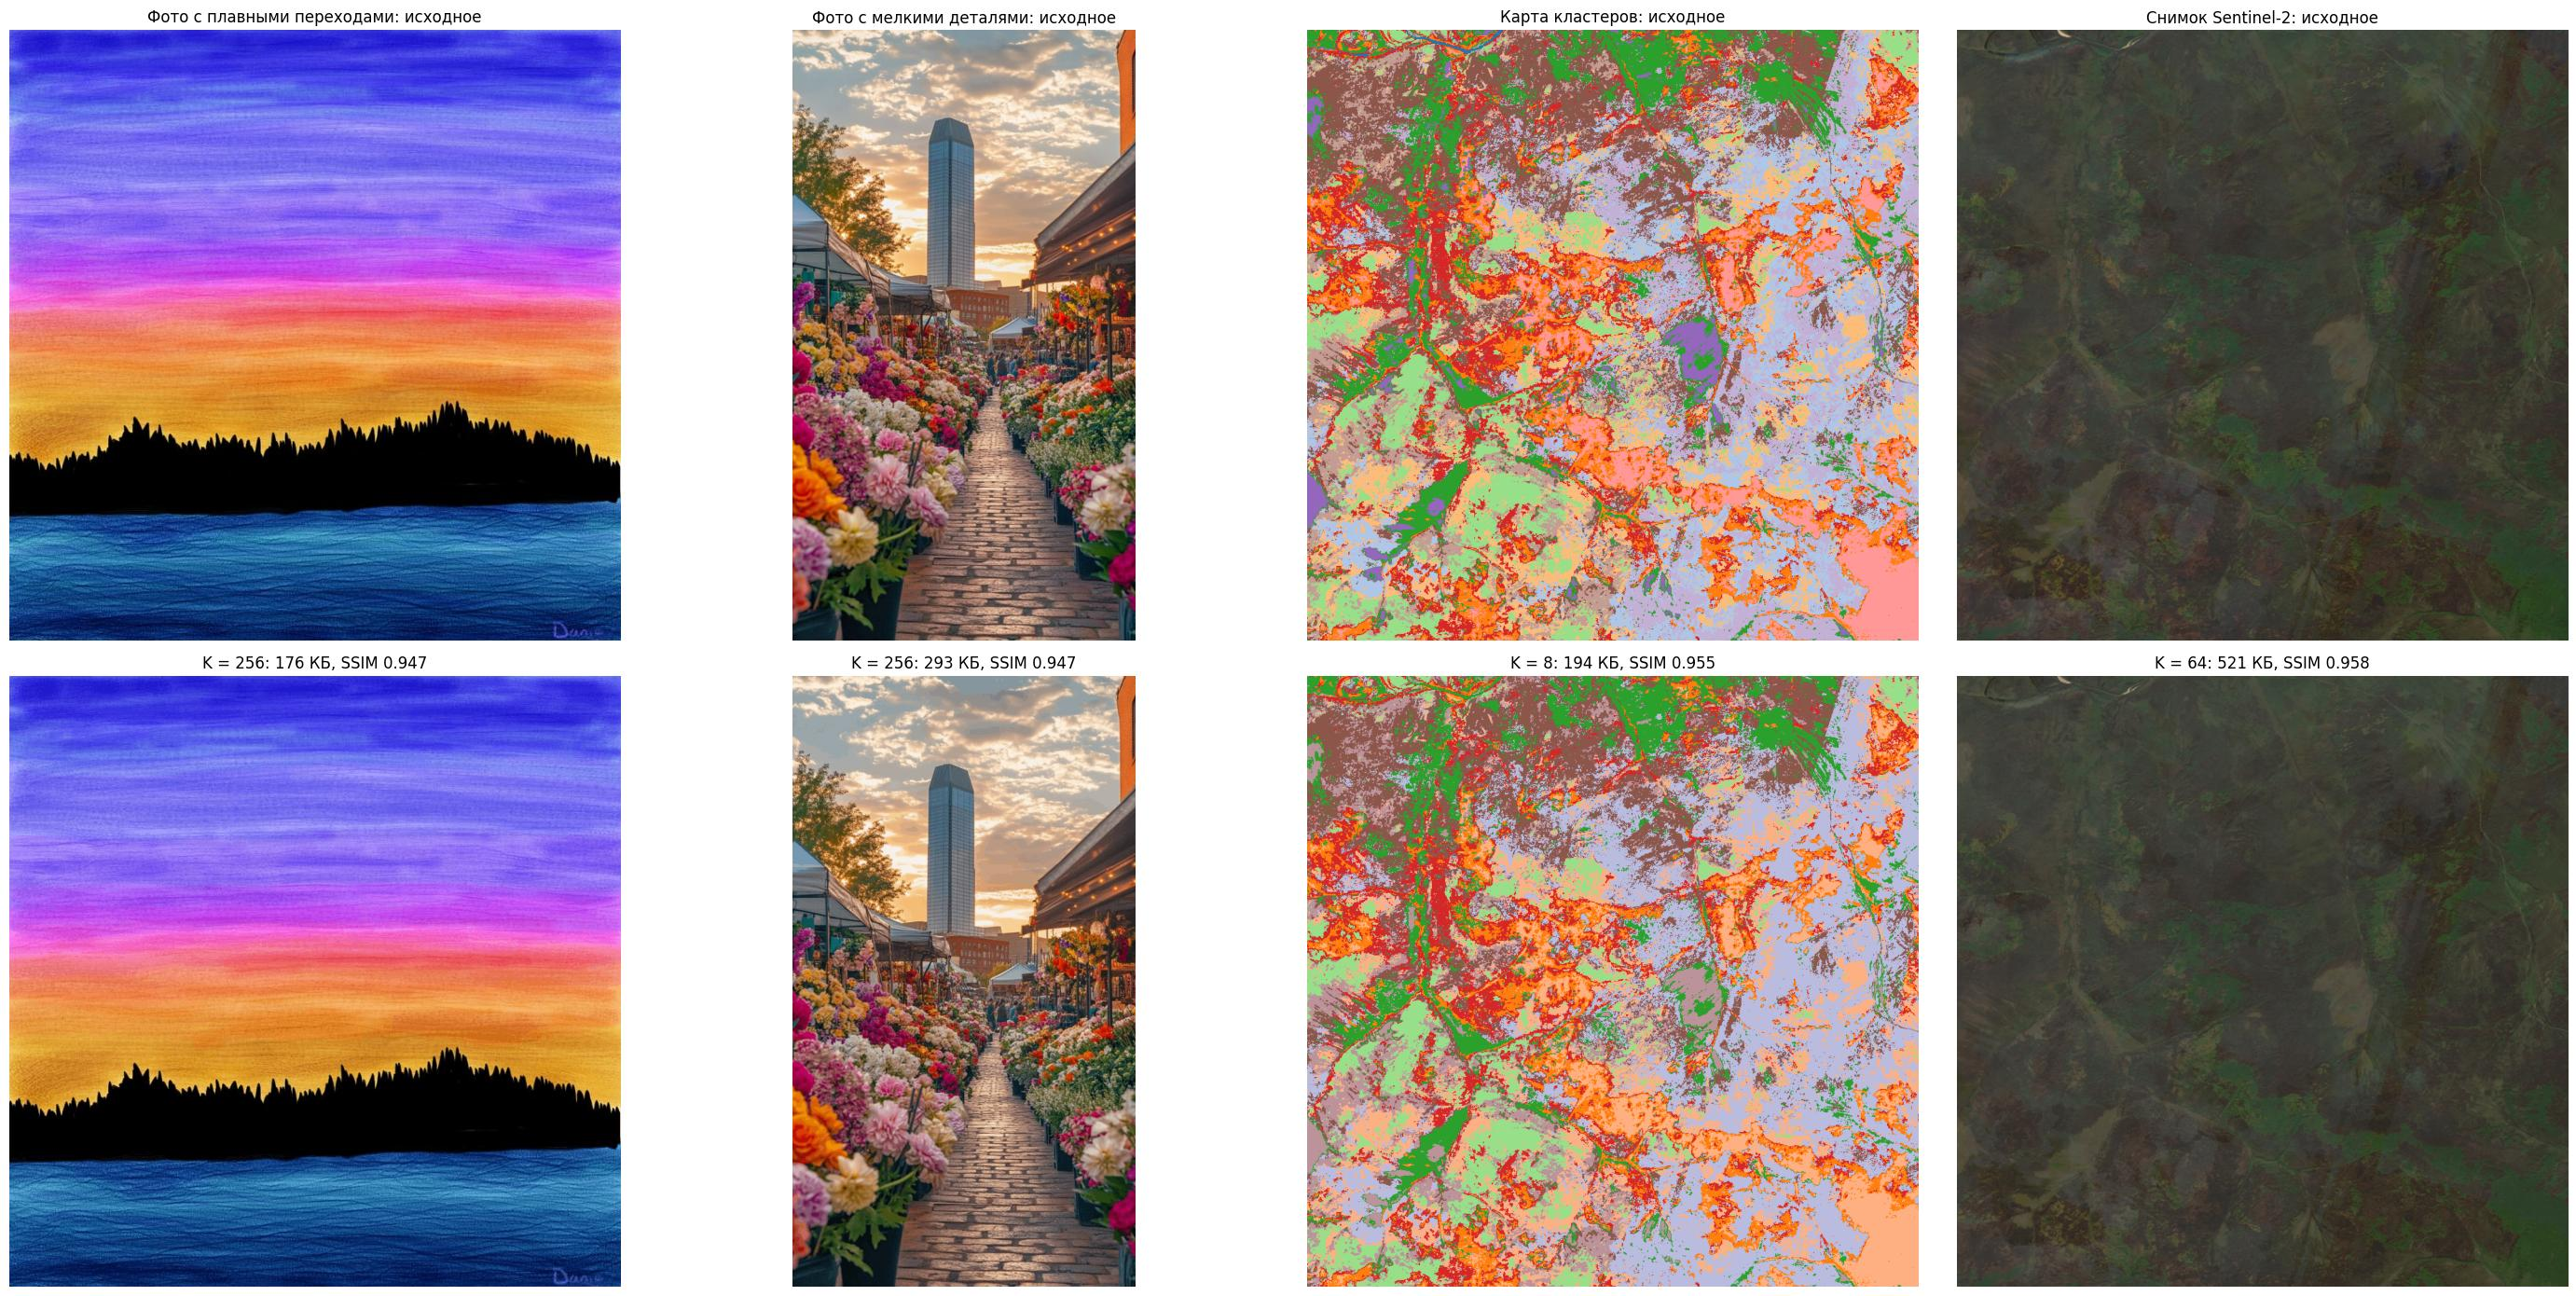

In [46]:
# @title Готовый код: исходные изображения и выбранное число цветов
fig, axes = plt.subplots(2, len(images), figsize=(7 * len(images), 14))
if len(images) == 1:
    axes = axes.reshape(2, 1)
for j, (name, img) in enumerate(images.items()):
    k = int(choice_df.loc[name, "K"])
    palette, indices = quantized[(name, k)]
    axes[0, j].imshow(img)
    axes[0, j].set_title(f"{name}: исходное")
    axes[1, j].imshow(palette[indices])
    kb = choice_df.loc[name, "Палитровый PNG, КБ"]
    ssim = choice_df.loc[name, "SSIM"]
    axes[1, j].set_title(f"K = {k}: {kb:.0f} КБ, SSIM {ssim:.3f}")
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

**Вопрос:** Для каких изображений палитровый PNG при малозаметных искажениях меньше JPEG 90, а для каких — больше? Чем отличаются эти изображения? Какой способ хранения вы выберете для фотографий, для тематических карт и для снимков в естественных цветах?

**Ответ:**
PNG< JPEG

Для карты кластеров в PNG 193.68 а в JPEG 621.09. Скорее всего из-за того что карта кластеров имеет строго ограниченый набор цветов и чёткие границы, хз из-за чего может быть ещё.

PNG> JPEG

все остальные

Для карт использовать PNg для всех остальных JPEG.

### **6.8. Выводы по разделу 6**

Опишите, при каких условиях кластеризация цветов уменьшает размер файла, как правильно сохранять результат, как связаны число цветов, размер и качество, и чем K-средних отличается от встроенной квантизации.

**Вывод:**
Уменьшает размер файла, при:

Типе изображения, например при фото заката, неба, тематической карты с фик набором цветов. Где есть плавный градиент и большие однородные области. При палтировом PNG.

Нужно обязательно сохранять в формате палитроваго PNG

Чем меньше K тем меньше размер файла, но подение качества, и наоборот. Для изображение в работе выяснили что 16 золотая середина.



---

## **7. Итоговые выводы**

В выводах обязательно отразить:
1. **Территория и найденные объекты**: что нашла кластеризация, их площадь, вид в естественных цветах и в инфракрасных каналах;
2. **Классификация по Dynamic World**: точность при случайной и пространственной проверке, лучший классификатор, проблемные классы, совпадение карты с Dynamic World;
3. **Классификация и кластеризация**: что может и чего не может каждый подход на вашей территории;
4. **Сжатие изображений**: для каких изображений и при каком числе цветов кластеризация выгодна, во сколько раз уменьшается размер;
5. **Возможное практическое применение** полученных результатов.

**Выводы:**

1. Территория и найденные объекты
Исследование проводилось на горно-таёжной территории Забайкальского края (координаты центра: 54.665 с.ш., 118.893 в.д.). С помощью автоматического алгоритма кластеризации K-means оптимальное число кластеров K=12 удалось детально определдить ключевые природные объекты:

Коренная хвойная тайга «Иголки»: Занимает доминирующую площадь в 5431.5 га. В естественных цветах (RGB) выглядит как монотонный, очень темный зеленовато-бурый массив. В инфракрасном синтезе B12–B8–B4 она резко выделяется насыщенным, неоново-зеленым цветом.

Старые и свежие гари (Кластеры 10 и 3): Суммарно занимают около четверти всей площади снимка (самый крупный Кластер 10 — 2679.83 га, Кластер 3 — 2082.48 га), что подтверждает огромную роль пожаров в регионе. Глазами в RGB они почти неотличимы от живого леса, но в ИК-каналах SWIR (B11, B12) они «вспыхивают» контрастными бордово-красными и кирпичными оттенками из-за сильного дефицита влаги и высокой отражательной способности обгоревшей почвы.

Каменистые россыпи и гольцы (Кластер 11): Занимают 1675.68 га на самых вершинах хребтов. В RGB выглядят как светлые, серые зернистые текстуры, а в ИК-диапазоне дают специфический сине-голубой профиль обнаженных горных пород.

Нарушенные лесозаготовками земли и вырубки (Кластер 9): Занимают 2192.98 га. Имеют строгие геометрические контуры, незаметные в RGB, но ярко проявляющиеся в ИК-диапазоне за счет буйного роста молодой травяной растительности на месте спиленного леса.

Гидрографическая сеть (Кластер 0): Открытая вода занимает всего 53.08 га (0.27% территории). В RGB и ИК-каналах выглядит глубоким черным цветом, так как вода полностью поглощает инфракрасные лучи (значение канала B8 составляет -1.834). При анализе 0,1% самых необычных пикселей* (с показателем аномальности 9.529) алгоритм выявил скрытые песчаные косы и мелководья, которые легко пропустить при обычном визуальном просмотре.

2. Классификация по Dynamic World
При обучении модели контролируемой классификации Random Forest тобишь Случайный лес, на основе данных глобальной карты Dynamic World были получены следующие результаты:

Влияние валидации: При оптимистичной случайной проверке модель показала ложнозавышенные метрики (Accuracy = 0.7348, Kappa = 0.6905). Однако при честной пространственной проверке (по изолированным географическим блокам) точность закономерно снизилась на 6.7% (Accuracy = 0.6680), а Каппа — на 7.9% (Kappa = 0.6114). Для экстраполяции модели на соседние участки тайги доверять можно только пространственной оценке, так как случайная проверка игнорирует географическую автокорреляцию пикселей.

Лучший классификатор и признаки: Случайный лес показал себя наилучшим образом. Главный вклад в обучение внесли каналы невидимого спектра: SWIR-каналы (B11 и B12) и ближний ИК (B8 вместе с индексами NDVI, NDWI, NBR), которые суммарно обеспечили 71.40% всей важности признаков.

Проблемные классы:Лучше всего модель распознает Воду*(точность 0.85) и сомкнутые Деревья. Самым проблемным классом оказались Кустарники* (точность всего 50%), которые алгоритм путает с Культурами (16%) и *Деревьями (11%). Это объясняется эффектом «смешанного пикселя» (10-метровое разрешение Sentinel-2) и спектральным сходством хлорофилла в зелёной биомассе.

Совпадение карт: Доля прямого совпадения вашей карты с Dynamic World составила всего 58.63%. Несовпадения сосредоточены в виде мелкого мозаичного шума на склонах гор, вдоль речных долин и на границах лесных массивов. Модель зафиксировала колоссальный перекос по классу Культуры (рост площадей почти в 9 раз — с 317 до 2847 тыс. га) и Вода (рост в 5 раз), ошибочно приняв молодую поросль на гарях за пашни, а глубокие горные тени — за воду.

3. Сравнение подходов: Классификация vs Кластеризация
Эксперимент наглядно показал сильные и слабые стороны обоих методов:

Контролируемая классификация (Random Forest):

Что может: Эффективно разделяет стабильные макроклассы (воду от леса) и позволяет быстро тиражировать карту на огромные площади по готовым эталонам.

Чего не может: Она жестко зажата рамками глобальной легенды. Модель не способна выделить чисто таёжные объекты («гарь», «вырубку», «курумник»), заставляя пользователя совершать системные ошибки (например, искать несуществующие сельскохозяйственные культуры в глухой тайге). Кроме того, она копирует и удваивает ошибки готовой карты Dynamic World.

Неконтролируемая кластеризация (K-means):

Что может: Обладает гибкостью и способна выделять реальные спектральные аномалии на местности, которых вообще нет в официальных легендах (четко отделяет сухие выгоревшие гари от влажных болот и вырубок).

Чего не может:* Не дает объектам готовых географических названий. Требует обязательной экспертной интерпретации человеком по профилям каналов и долям классов, а также сильно зависит от рельефа ( hillshade-эффект путает тени гор с водой).

4. Сжатие изображений и цветовое квантование
Анализ методов уменьшения цветовой палитры (K-means и Median Cut) выявил следующие закономерности:

Где выгодно квантование: Кластеризация цвета экономически оправдана для «Фото с плавными переходами» (Закат) и Тематических карт. Для естественных фото с шумом и спутниковых снимков Sentinel-2 (с мелкой текстурой тайги) выигрыш ниже из-за частой сменяемости пикселей.

Оптимальное число цветов: Идеальной «золотой серединой» является K = 16$ цветов (4 бита на пиксель). На этом уровне файлы палитрового PNG уменьшаются в размере в 4–20 раз при сохранении высокого визуального качества (SSIM = 0.8–0.9), в то время как при K  64 файлы быстро толстеют, а время квантования K-means растет взрывным, нелинейным образом (до 4 секунд на снимок).

Метод-лидер: Алгоритм K-means по всем параметрам превосходит встроенный Median Cut: он дает качество изображения (PSNR) выше на 1.5 – 3.71 дБ и формирует более легкие файлы (за счет создания крупных однородных зон, которые PNG-архиватор сжимает эффективнее).

Правила сохранения: Результат необходимо сохранять исключительно в палитровом PNG (Indexed). Сохранение в RGB-PNG раздувает вес файла в 1.5–2.7 раза из-за пустых технических битов. Сохранение в JPEG для квантованных картинок противопоказано: на резких стыках цветов JPEG плодит цифровой шум и артефакты, увеличивая вес файла (на примере карты кластеров JPEG весит 621 КБ против 193 КБ у палитрового PNG).

Размер подвыборки: При обучении квантования рекомендуется использовать подвыборку из 50 000 пикселей. Она сокращает время работы процессора в 19 раз (с 9.88 с до 0.52 с) по сравнению со стопроцентной выборкой, теряя при этом ничтожные 0.04 дБ качества (PSNR), что неощутимо для глаза.

5. Практическое применение результатов
Полученные в проекте алгоритмы и выводы имеют прямую практическую ценность в следующих областях:

Экологический мониторинг и охрана лесов (Пирогенный контроль): Выделенные оптические профили гарей (Кластеры 10 и 3) позволяют автоматизировать обнаружение лесных пожаров в Забайкальском крае на ранних стадиях, а также с высокой точностью рассчитывать площади и границы выгоревших таёжных массивов для оценки ущерба Рослесхозом.

Контроль недропользования и добычи золота: На основе комбинации ИК-каналов и детекции аномалий (0,1% необычных пикселей) можно в автоматическом режиме выявлять незаконные поисковые шурфы, границы золотоносных приисков, карьеры и несанкционированные вырубки леса вдоль русел рек добывающими компаниями.

Оптимизация ГИС и геопорталов: Разработанная методика палитрового квантования (K=16, K-means, Indexed PNG) позволяет в 4–20 раз уменьшить вес спутниковых снимков и тематических карт, загружаемых на сервера. Это критически важно для создания быстрых мобильных карт ведомственного мониторинга, работающих в условиях слабого спутникового интернета в глухой тайге Сибири и Дальнего Востока.


---

## **Что сдавать**

1. Выполненный блокнот со всеми выводами ячеек и заполненными ответами (таблицы 2 и 3, ответы на вопросы, выводы по разделам 4–6 и итоговые выводы).
2. Папку `compressed` с файлами раздела 6 (в архиве).

## **Дополнительные задания (выполняются по желанию)**

1. **Перенос модели.** Примените классификатор, обученный на своей территории, к композиту другой территории из таблицы 1 и рассчитайте совпадение с Dynamic World. Сравните с точностью пространственной проверки и объясните разницу.
2. **Поиск по эталону.** Возьмите центроиды «иголок» своей территории и найдите на другой территории пиксели, ближе всего к ним расположенные в пространстве стандартизированных признаков. Нашлись ли объекты того же типа?
3. **Собственная реализация K-средних.** Напишите K-средних для цветов на NumPy (инициализация, назначение пикселей, пересчёт центроидов, остановка по сдвигу центроидов) и сравните с `KMeans` по времени, числу итераций и PSNR при $K = 16$.
4. **Другое цветовое пространство.** Выполните квантизацию фотографий в пространстве CIELAB (`skimage.color.rgb2lab`), где евклидово расстояние ближе к различию цветов, воспринимаемому глазом, и сравните SSIM с квантизацией в RGB при одинаковом $K$.